In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import sys
import astropy as ast
import matplotlib.pyplot as plt
import pandas as pd
import glob
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import matplotlib.path as mpath
from pathlib import Path
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FormatStrFormatter, FuncFormatter
import mesa_reader as mr
fourpointstar = mpath.Path.unit_regular_star(4)
sevenpointstar = mpath.Path.unit_regular_star(7)
eightpointstar = mpath.Path.unit_regular_star(8)
from metrics_newlcs_sept26 import fit_plotter_flux, compute_lomb_scargle, plot_periodogram, info, plot_phase_fold_binned, plot_phase_fold

In [2]:
# sample = pd.read_csv(
#     './ysg_candidates_Tcut_nocontaminants_08272026.csv'
# ).set_index('star_idx', drop=False)

sample = pd.read_csv(
    './summary_results09222026.csv'
).set_index('star_idx', drop=False)

Number of stars in first bin (0-10 days): 9


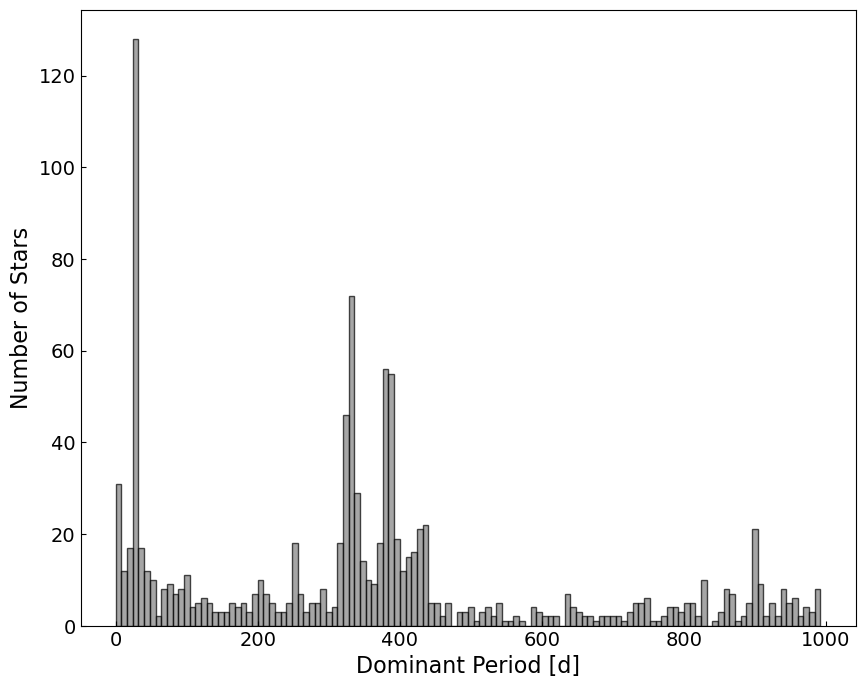

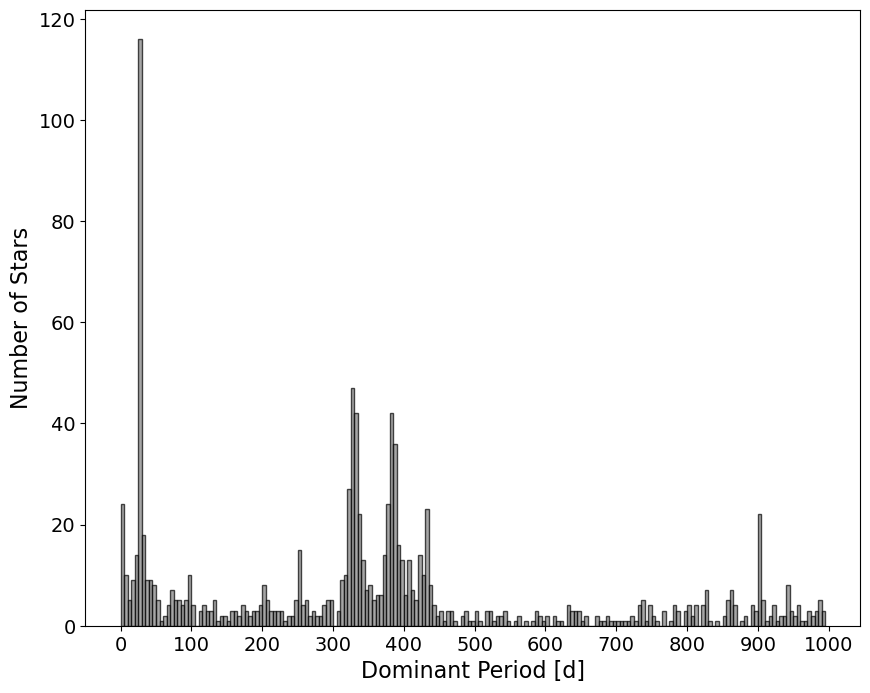

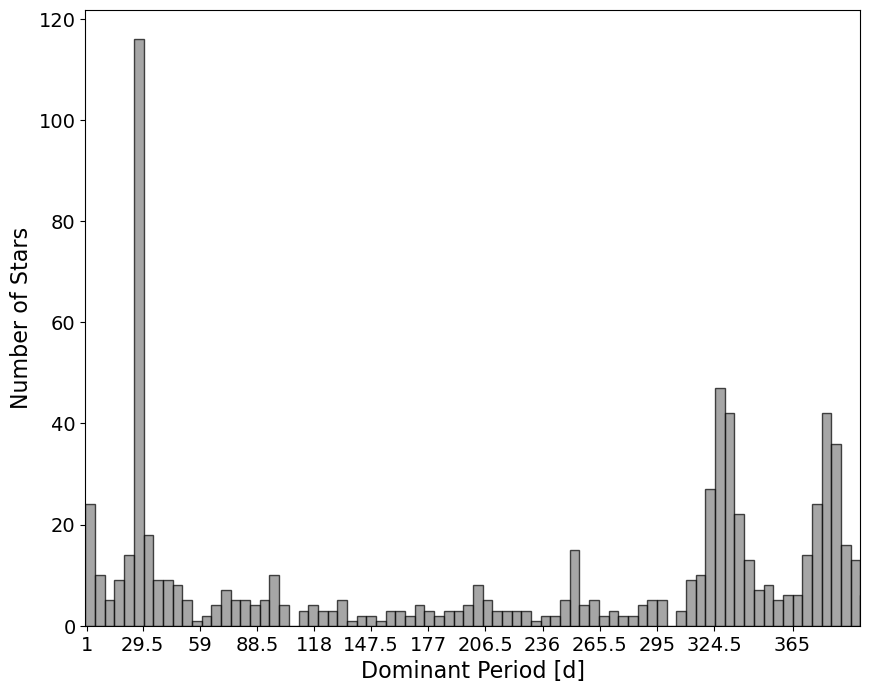

In [9]:
# histogram of periods

fig, ax = plt.subplots(figsize=(10, 8))
ax.hist(sample['best_period'], bins=np.arange(0, 1000, 8), alpha=0.7, color='grey', edgecolor='black')
# print the number ni the first bin
print(f"Number of stars in first bin (0-10 days): {np.sum((sample['best_period'] >= 0) & (sample['best_period'] < 2))}")
ax.set_xlabel("Dominant Period [d]", fontsize=16)
ax.set_ylabel("Number of Stars", fontsize=16)
ax.tick_params(axis="both", direction="in", labelsize=14)
plt.savefig("./figs/period_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
ax.hist(sample['best_period'], bins=np.arange(0, 1000, 5), alpha=0.7, color='grey', edgecolor='black')
ax.set_xlabel("Dominant Period [d]", fontsize=16)
ax.set_ylabel("Number of Stars", fontsize=16)
ax.tick_params(axis="both", direction="out", labelsize=14)
# ax.set_xlim(0,400)
# diy markers on the x axis
# xticks = [1.0, 29.5, 29.5*2, 29.5*3, 29.5*4, 29.5*5, 29.5*6, 29.5*7, 29.5*8, 29.5*9, 29.5*10, 29.5*11, 365]
# ax.set_xticks(xticks)
# ax.set_xticklabels(['1', '29.5', '59', '88.5', '118', '147.5', '177', '206.5', '236', '265.5', '295', '324.5', '365'])
ax.set_xticks(np.arange(0, 1001, 100))
plt.savefig("./figs/period_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
ax.hist(sample['best_period'], bins=np.arange(0, 1000, 5), alpha=0.7, color='grey', edgecolor='black')
ax.set_xlabel("Dominant Period [d]", fontsize=16)
ax.set_ylabel("Number of Stars", fontsize=16)
ax.tick_params(axis="both", direction="out", labelsize=14)
ax.set_xlim(0,400)
# diy markers on the x axis
xticks = [1.0, 29.5, 29.5*2, 29.5*3, 29.5*4, 29.5*5, 29.5*6, 29.5*7, 29.5*8, 29.5*9, 29.5*10, 29.5*11, 365]
ax.set_xticks(xticks)
ax.set_xticklabels(['1', '29.5', '59', '88.5', '118', '147.5', '177', '206.5', '236', '265.5', '295', '324.5', '365'])
# ax.set_xticks(np.arange(0, 401, 50))
# plt.savefig("./figs/period_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
# let's pull out targets within a certain period range
lunar_cycle_range = (29.5 - 0.3, 29.5 + 0.3)
sample_lunar = sample[(sample['best_period'] >= lunar_cycle_range[0]) & (sample['best_period'] <= lunar_cycle_range[1])]
print(f"Number of stars with periods within {lunar_cycle_range[0]} and {lunar_cycle_range[1]} days: {len(sample_lunar)}")
print(sample_lunar[['star_idx', 'best_period']])



other_alias_range = (328 - 5, 328 + 5)
other_alias = sample[(sample['best_period'] >= other_alias_range[0]) & (sample['best_period'] <= other_alias_range[1])]
other_alias_320 = other_alias[other_alias["alarm_level_flag"]==0]
print(f"Number of stars with periods within {other_alias_range[0]} and {other_alias_range[1]} days: {len(other_alias)}")
print(other_alias_320[['star_idx', 'best_period']])

other_alias_range_380 = (380 - 5, 380 + 5)
other_alias_380 = sample[(sample['best_period'] >= other_alias_range_380[0]) & (sample['best_period'] <= other_alias_range_380[1])]
other_alias_380 = other_alias_380[other_alias_380["alarm_level_flag"]==0]
print(f"Number of stars with periods within {other_alias_range_380[0]} and {other_alias_range_380[1]} days: {len(other_alias_380)}")
print(other_alias_380[['star_idx', 'best_period']])

Number of stars with periods within 29.2 and 29.8 days: 97
          star_idx  best_period
star_idx                       
23              23    29.528910
30              30    29.528526
46              46    29.543057
62              62    29.528374
64              64    29.470125
...            ...          ...
1139          1139    29.512352
1141          1141    29.558359
1142          1142    29.543672
1173          1173    29.584119
1242          1242    29.512628

[97 rows x 2 columns]
Number of stars with periods within 323 and 333 days: 91
          star_idx  best_period
star_idx                       
8                8   332.894536
9                9   329.907652
18              18   326.868804
39              39   332.424193
50              50   329.995817
...            ...          ...
1179          1179   329.116456
1183          1183   329.469420
1192          1192   323.791001
1193          1193   323.203484
1263          1263   329.717571

[91 rows x 2 columns]
Number

Star index: 125, Best period: 326.8970679740031


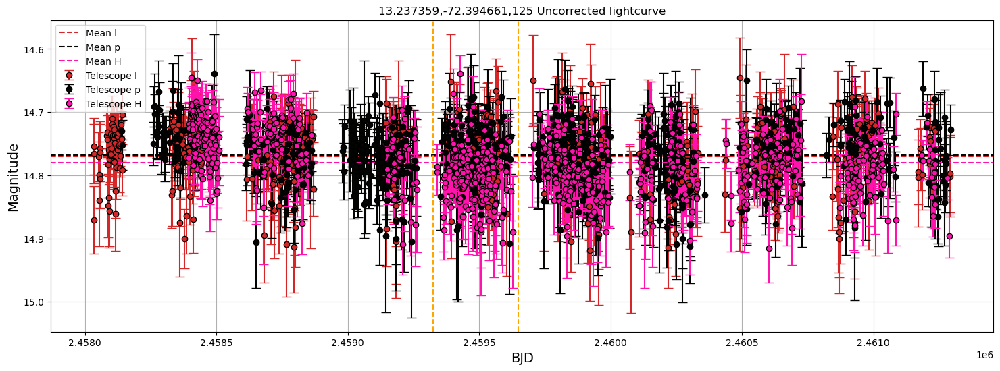

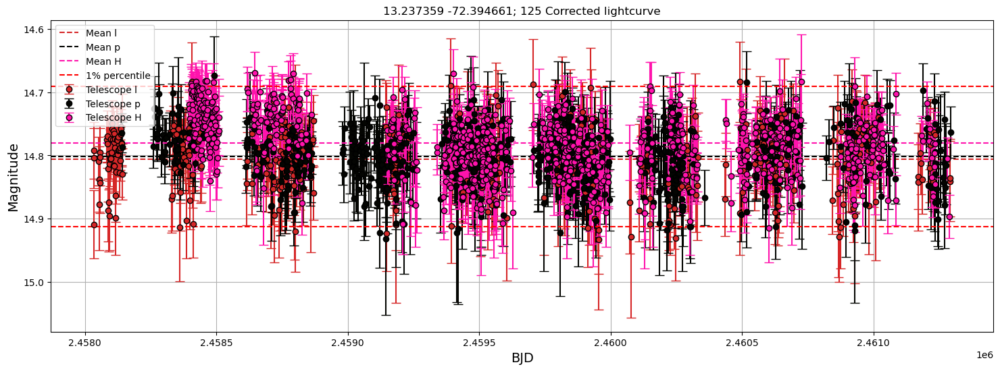

Best frequency: 0.003059 1/day, Best period: 326.90 days, Max power: 0.039, False alarm probability: 4.442e-13
False alarm level for 1.0%: 1.455e-02
Grid sampled at 17654 points


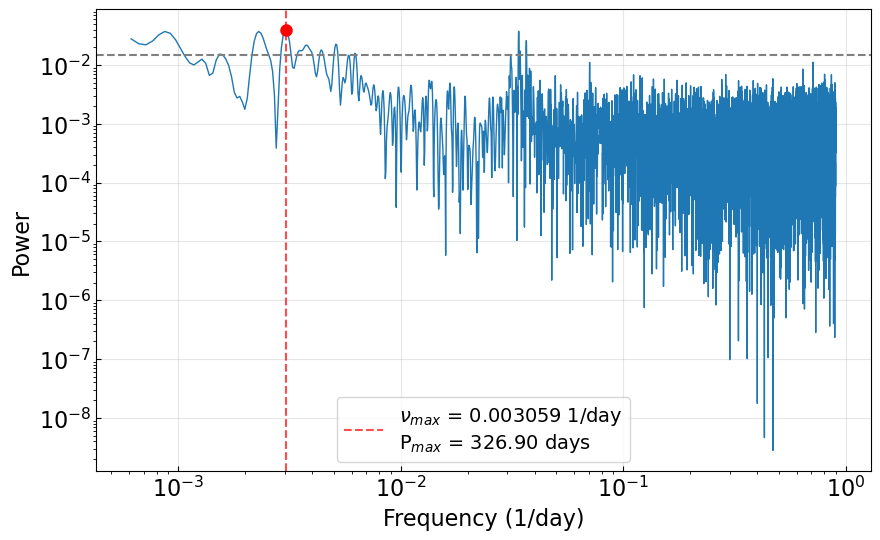

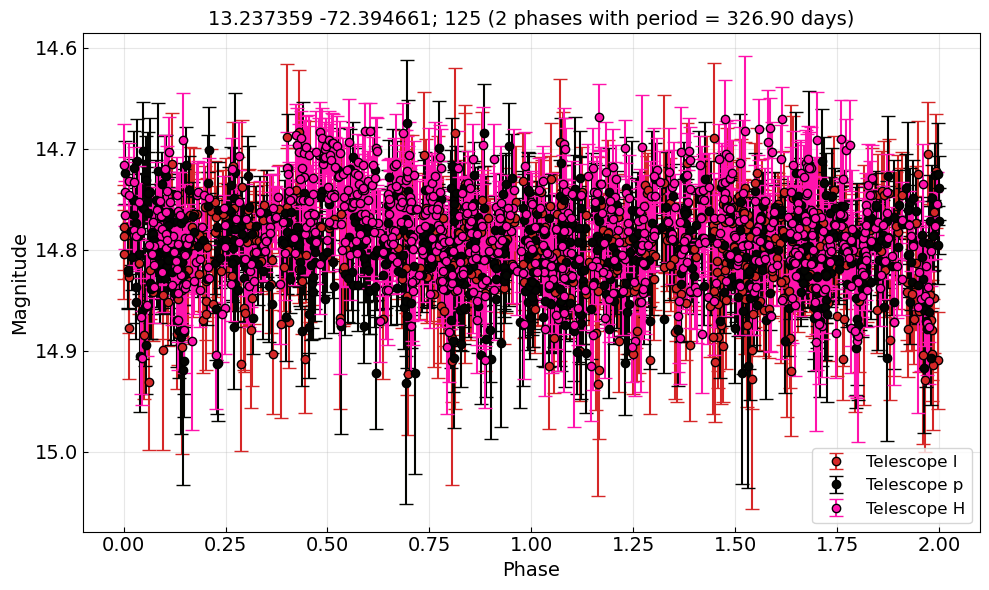

Average scatter (amplitude) per 10 point phase bin: 0.526 mJy


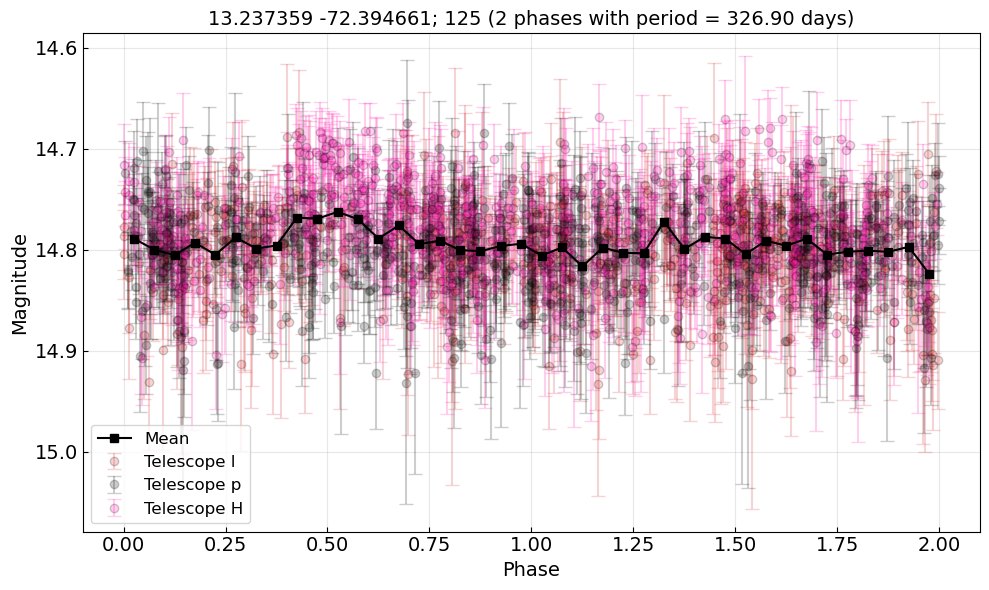

Average scatter (amplitude) per 10 point phase bin: 0.526 mJy
[0.0008683  0.00153062 0.00229485 0.00305907 0.00377234 0.00438372
 0.00509699 0.00621785 0.03383171 0.03434119 0.03663385]
Amplitude metrics:
	Lower 5% percentile: 4.06 mJy, 14.72 mags
	Upper 5% percentile: 4.71 mJy, 14.88 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 0.64 mJy, 0.16 mags
Amplitude metrics:
	Lower 1% percentile: 3.94 mJy, 14.69 mags
	Upper 1% percentile: 4.83 mJy, 14.91 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 0.89 mJy, 0.22 mags
	Largest amplitude of variability (g-band: True): 1.06 mJy, 0.26 mags
	Average amplitude across all periods: 0.970 mJy
	Standard deviation of amplitudes: 0.034 mJy
	Average amplitude (0.970 mJy) is greater than 5 sigma (0.034 mJy). This indicates consistent variability across periods.
Star index: 137, Best period: 329.7690082017438


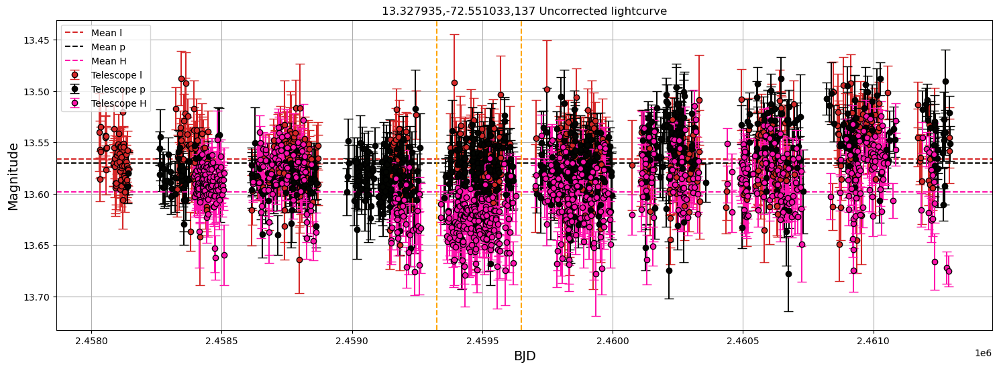

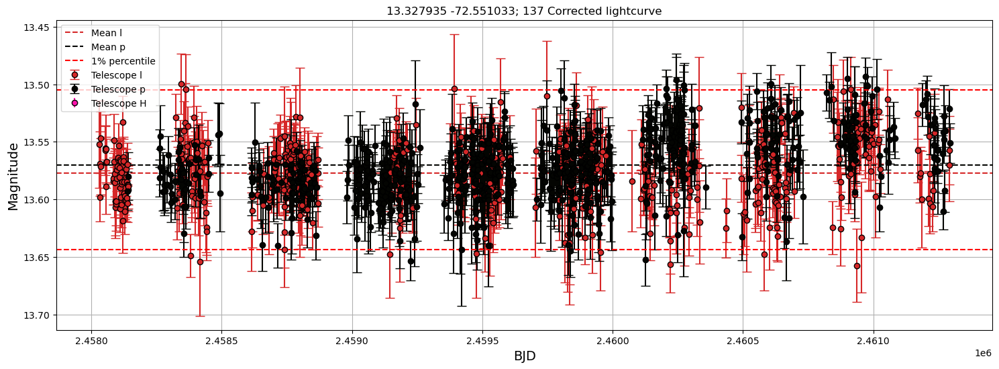

Best frequency: 0.003032 1/day, Best period: 329.77 days, Max power: 0.052, False alarm probability: 6.577e-11
False alarm level for 1.0%: 2.218e-02
Grid sampled at 11152 points


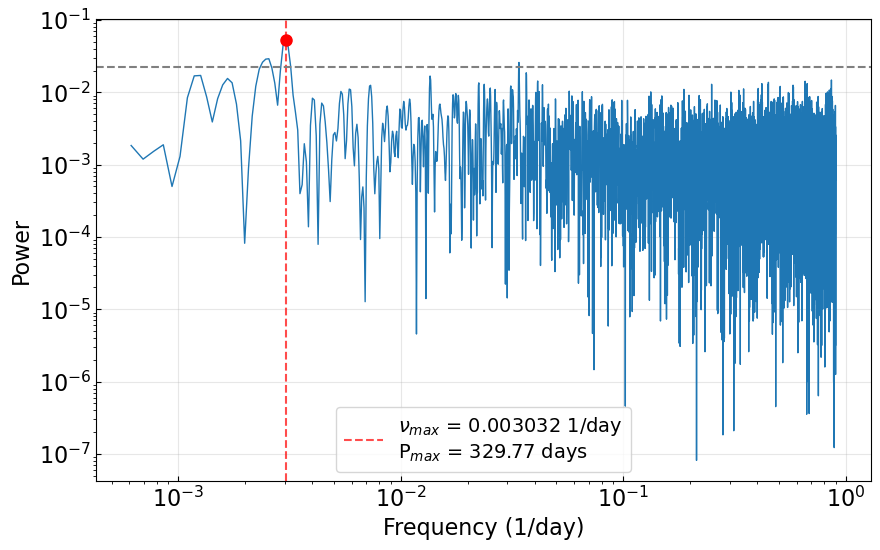

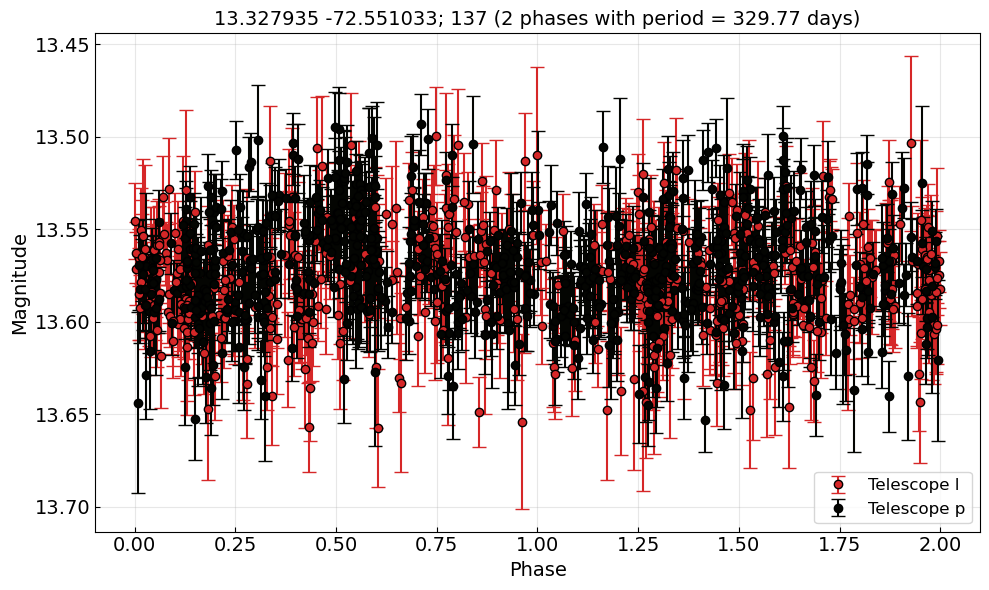

Average scatter (amplitude) per 10 point phase bin: 1.032 mJy


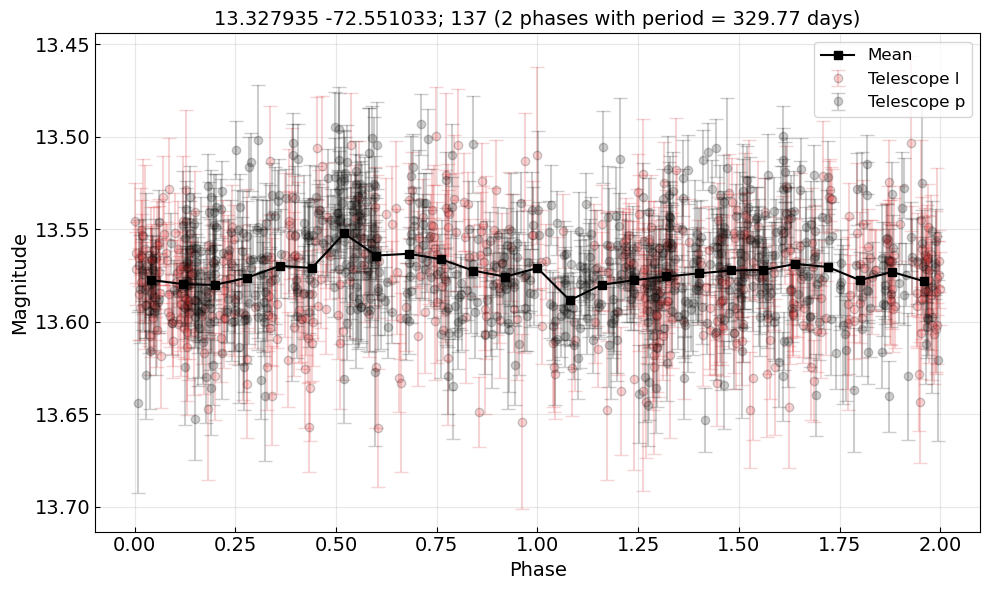

Average scatter (amplitude) per 10 point phase bin: 1.032 mJy
[0.00303243 0.0339234 ]
Amplitude metrics:
	Lower 5% percentile: 12.92 mJy, 13.53 mags
	Upper 5% percentile: 14.12 mJy, 13.62 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 1.20 mJy, 0.10 mags
Amplitude metrics:
	Lower 1% percentile: 12.67 mJy, 13.50 mags
	Upper 1% percentile: 14.39 mJy, 13.64 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.73 mJy, 0.14 mags
	Largest amplitude of variability (g-band: True): 2.04 mJy, 0.16 mags
	Average amplitude across all periods: 1.739 mJy
	Standard deviation of amplitudes: 0.269 mJy
	Average amplitude (1.739 mJy) is greater than 5 sigma (0.269 mJy). This indicates consistent variability across periods.
Star index: 139, Best period: 332.79162537857223


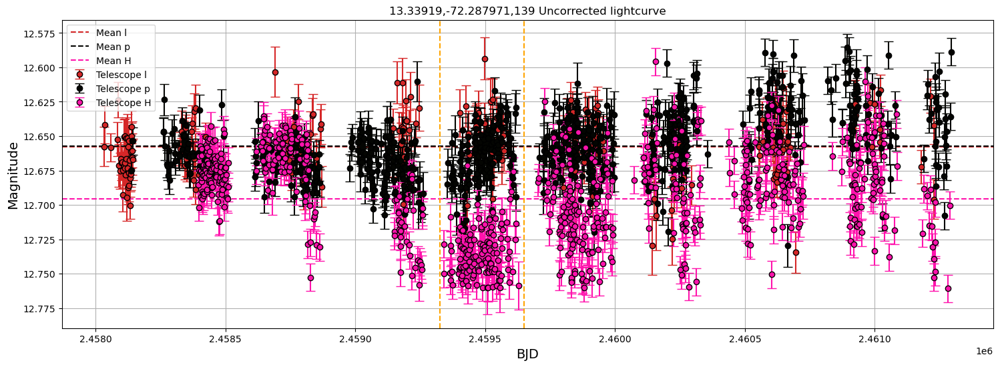

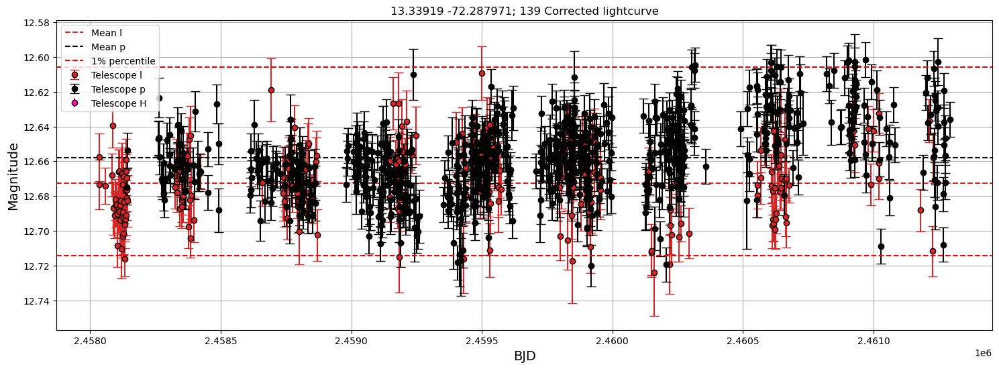

Best frequency: 0.003005 1/day, Best period: 332.79 days, Max power: 0.082, False alarm probability: 1.682e-14
False alarm level for 1.0%: 2.789e-02
Grid sampled at 8652 points


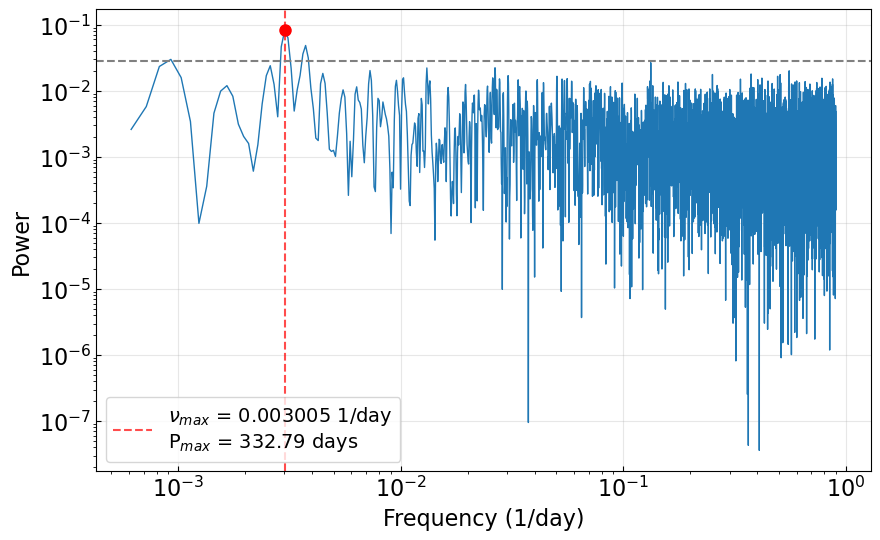

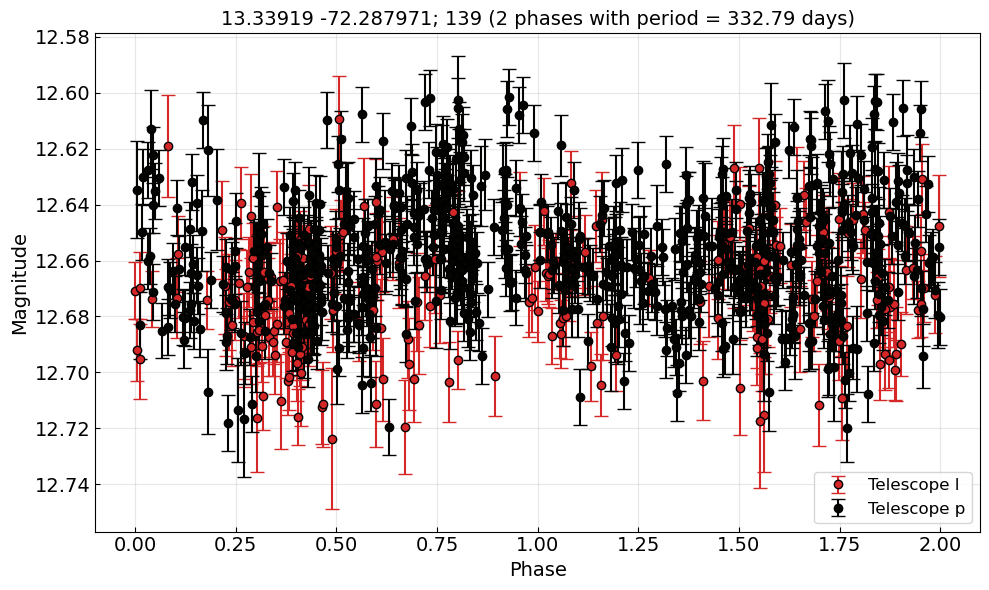

Average scatter (amplitude) per 10 point phase bin: 1.764 mJy


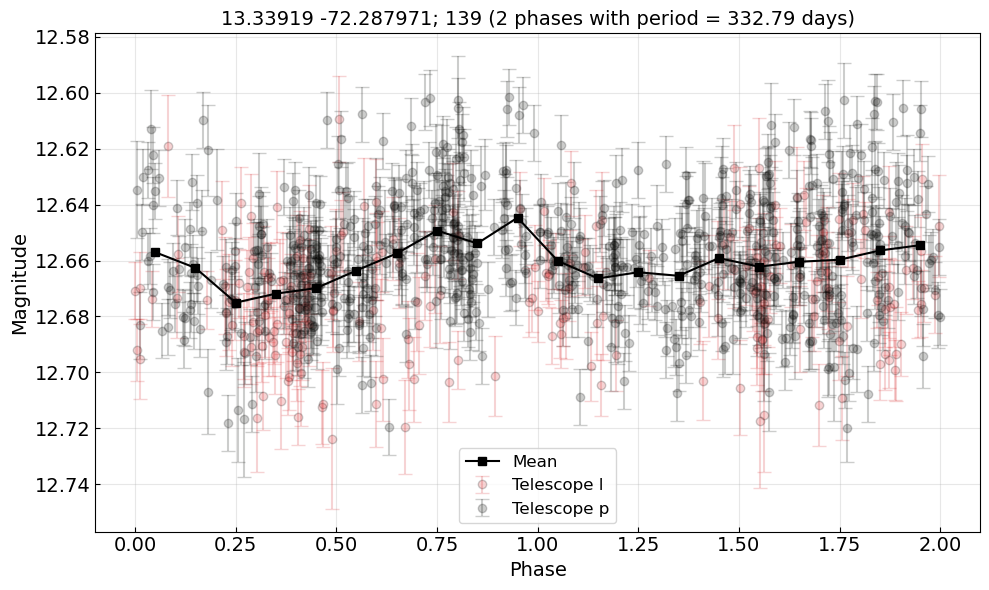

Average scatter (amplitude) per 10 point phase bin: 1.764 mJy
[0.00092562 0.00300488]
Amplitude metrics:
	Lower 5% percentile: 30.30 mJy, 12.62 mags
	Upper 5% percentile: 32.45 mJy, 12.70 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 2.15 mJy, 0.07 mags
Amplitude metrics:
	Lower 1% percentile: 29.81 mJy, 12.61 mags
	Upper 1% percentile: 32.94 mJy, 12.71 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 3.13 mJy, 0.11 mags
	Largest amplitude of variability (g-band: True): 3.52 mJy, 0.12 mags
	Average amplitude across all periods: 2.985 mJy
	Standard deviation of amplitudes: 0.317 mJy
	Average amplitude (2.985 mJy) is greater than 5 sigma (0.317 mJy). This indicates consistent variability across periods.
Star index: 148, Best period: 332.6647234364453


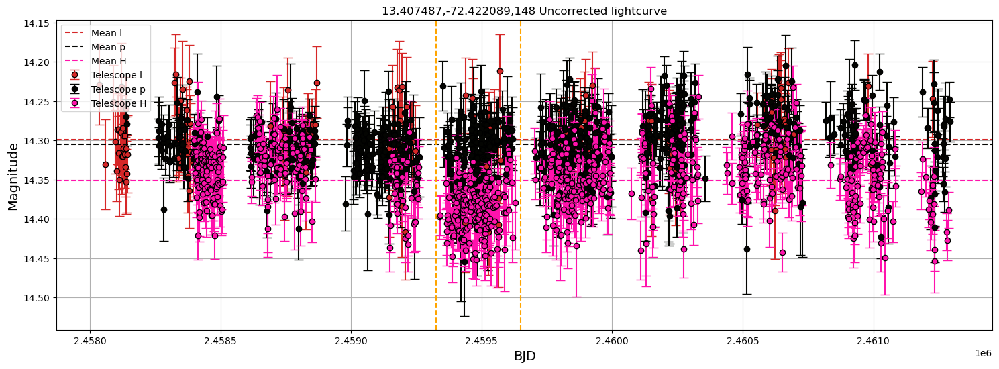

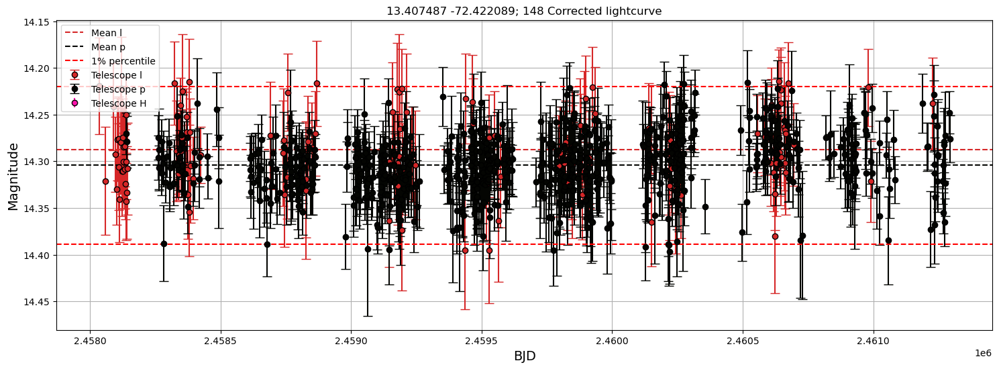

Best frequency: 0.003006 1/day, Best period: 332.66 days, Max power: 0.041, False alarm probability: 8.514e-05
False alarm level for 1.0%: 3.024e-02
Grid sampled at 7896 points


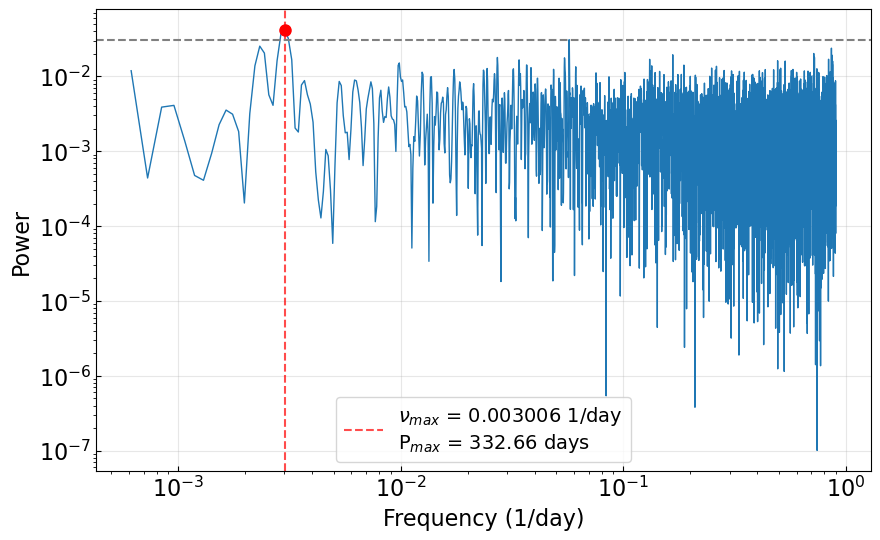

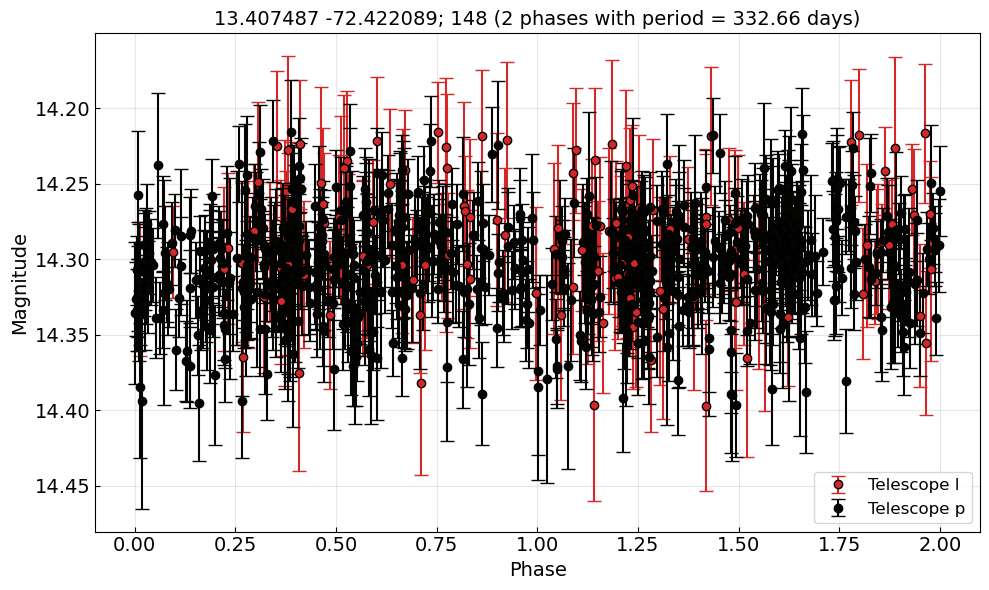

Average scatter (amplitude) per 10 point phase bin: 0.639 mJy


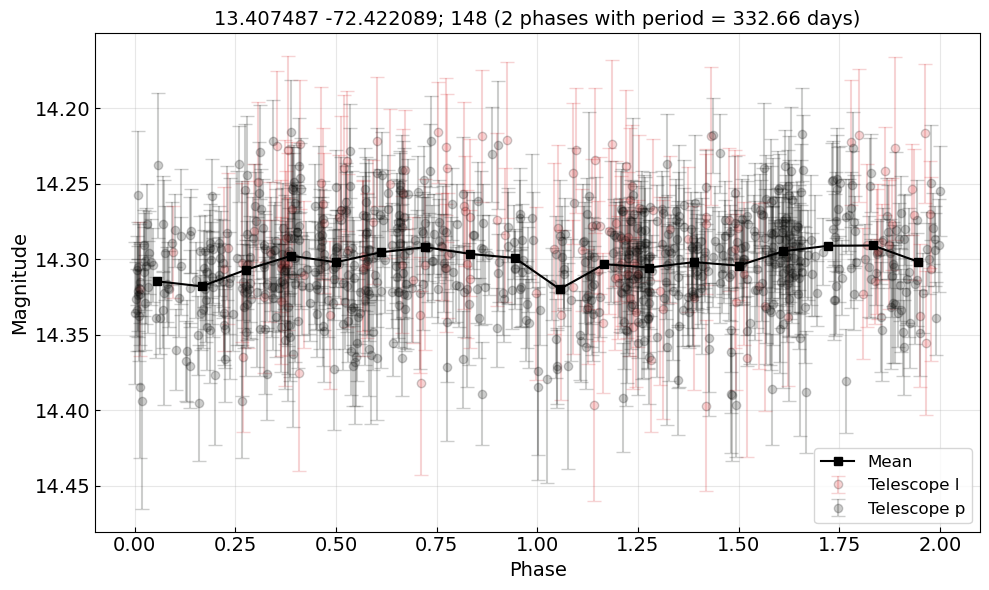

Average scatter (amplitude) per 10 point phase bin: 0.639 mJy
[0.00300603 0.05700338]
Amplitude metrics:
	Lower 5% percentile: 6.54 mJy, 14.24 mags
	Upper 5% percentile: 7.29 mJy, 14.36 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 0.75 mJy, 0.12 mags
Amplitude metrics:
	Lower 1% percentile: 6.37 mJy, 14.22 mags
	Upper 1% percentile: 7.45 mJy, 14.39 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.07 mJy, 0.17 mags
	Largest amplitude of variability (g-band: True): 1.16 mJy, 0.18 mags
	Average amplitude across all periods: 1.081 mJy
	Standard deviation of amplitudes: 0.036 mJy
	Average amplitude (1.081 mJy) is greater than 5 sigma (0.036 mJy). This indicates consistent variability across periods.
Star index: 155, Best period: 329.7957335196753


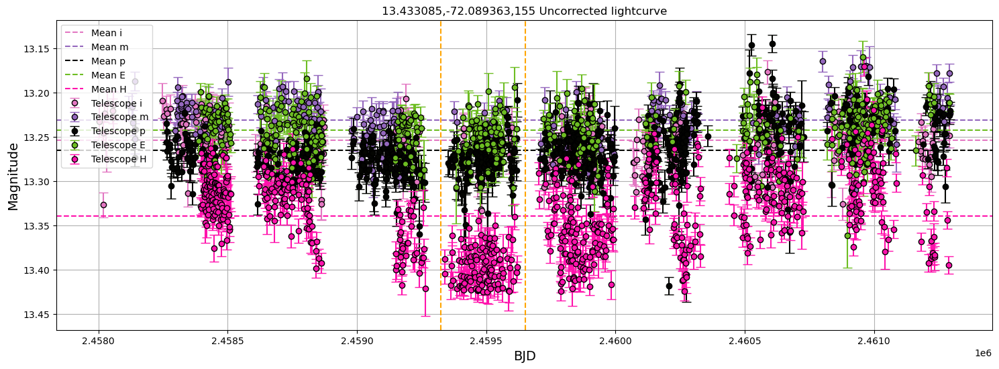

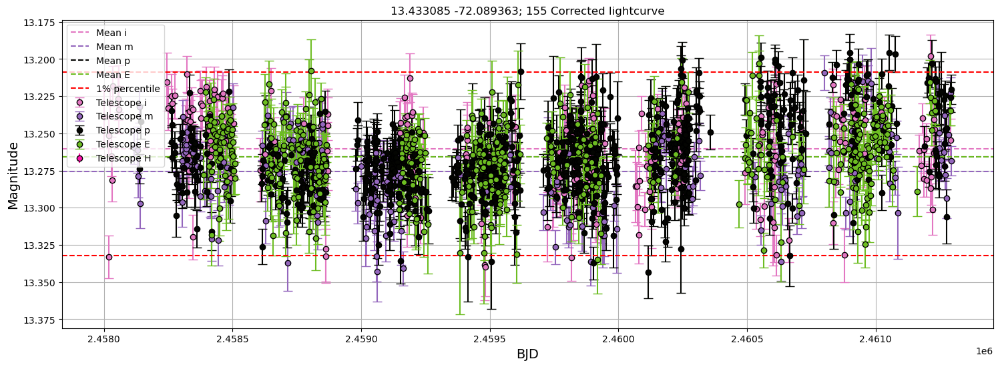

Best frequency: 0.003032 1/day, Best period: 329.80 days, Max power: 0.027, False alarm probability: 3.494e-06
False alarm level for 1.0%: 1.710e-02
Grid sampled at 14839 points


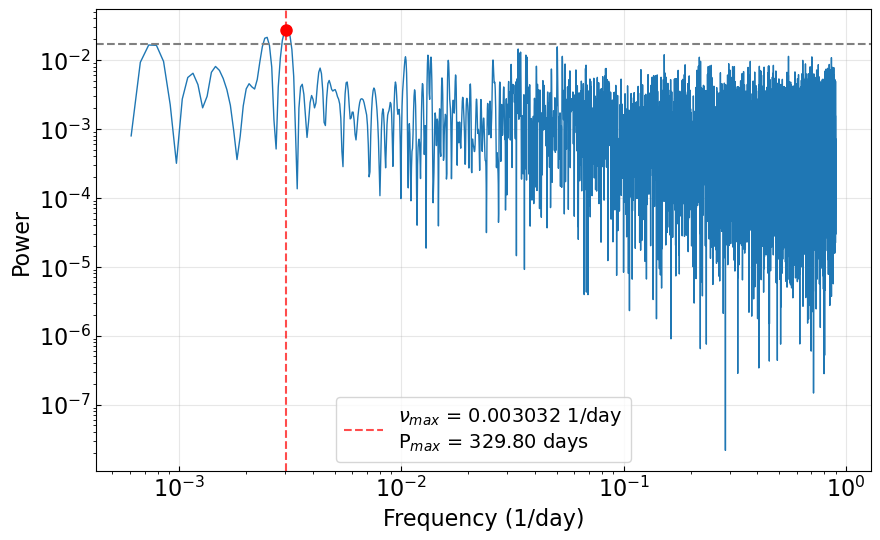

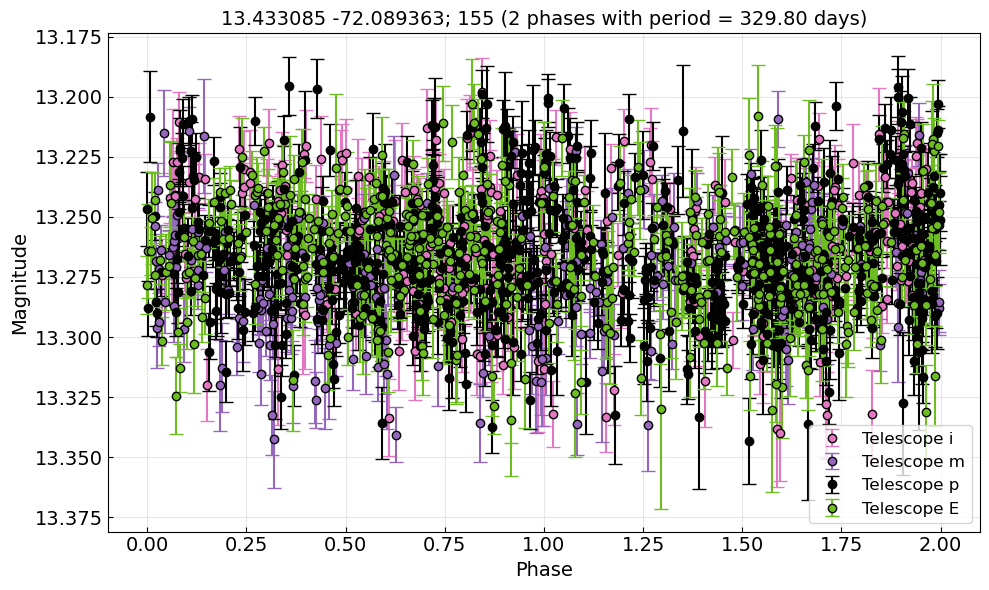

Average scatter (amplitude) per 10 point phase bin: 1.211 mJy


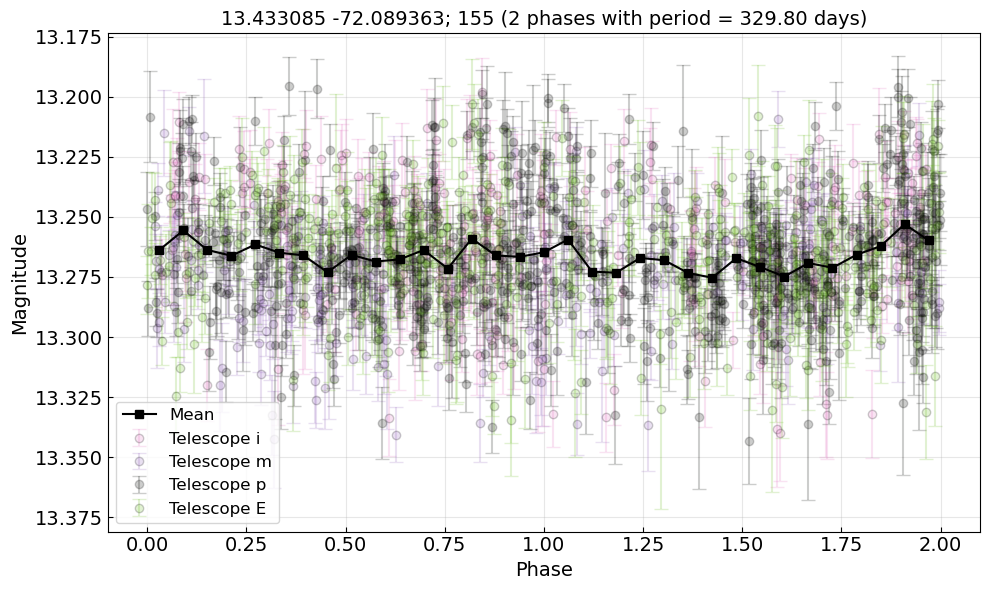

Average scatter (amplitude) per 10 point phase bin: 1.211 mJy
[0.00303218]
Amplitude metrics:
	Lower 5% percentile: 17.22 mJy, 13.22 mags
	Upper 5% percentile: 18.67 mJy, 13.31 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 1.45 mJy, 0.09 mags
Amplitude metrics:
	Lower 1% percentile: 16.87 mJy, 13.21 mags
	Upper 1% percentile: 18.90 mJy, 13.33 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 2.03 mJy, 0.12 mags
	Largest amplitude of variability (g-band: True): 2.43 mJy, 0.15 mags
	Average amplitude across all periods: 2.136 mJy
	Standard deviation of amplitudes: 0.135 mJy
	Average amplitude (2.136 mJy) is greater than 5 sigma (0.135 mJy). This indicates consistent variability across periods.
Star index: 163, Best period: 328.4957280246098


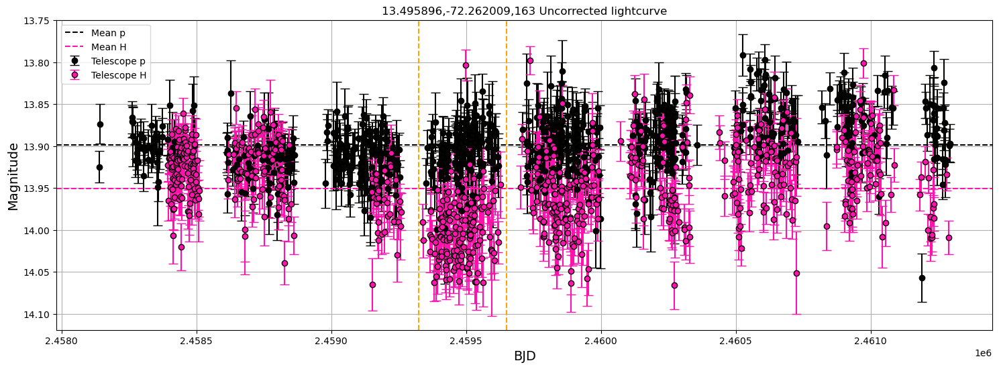

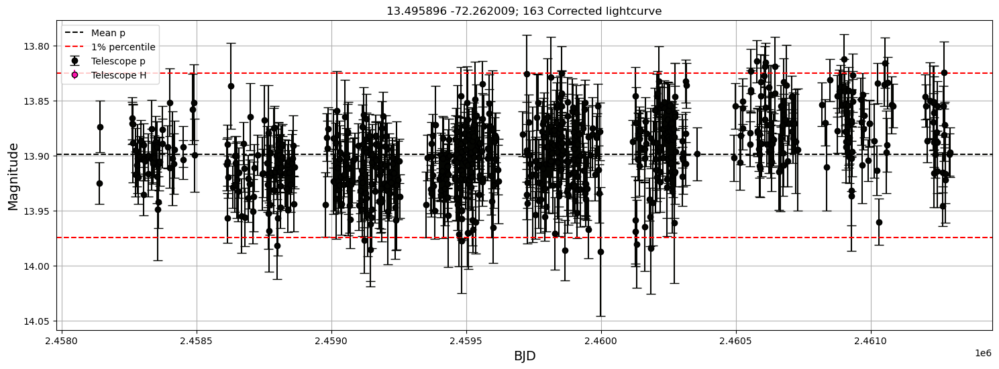

Best frequency: 0.003044 1/day, Best period: 328.50 days, Max power: 0.067, False alarm probability: 4.517e-08
False alarm level for 1.0%: 3.506e-02
Grid sampled at 6718 points


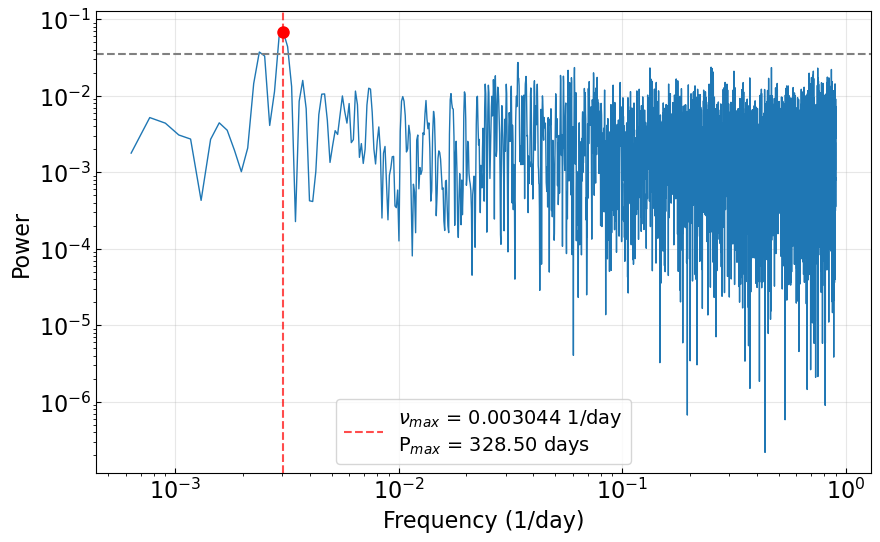

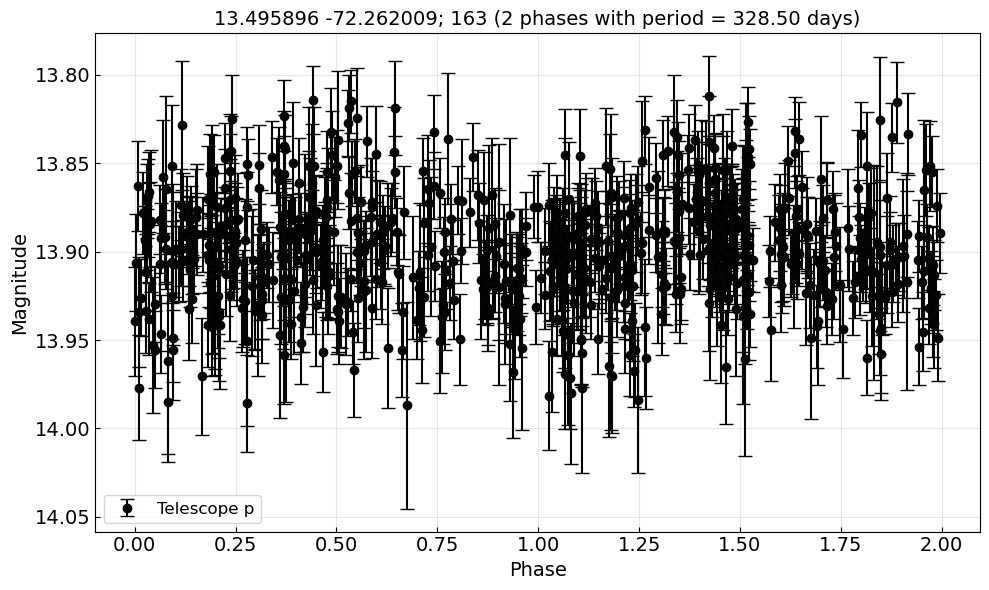

Average scatter (amplitude) per 10 point phase bin: 0.833 mJy


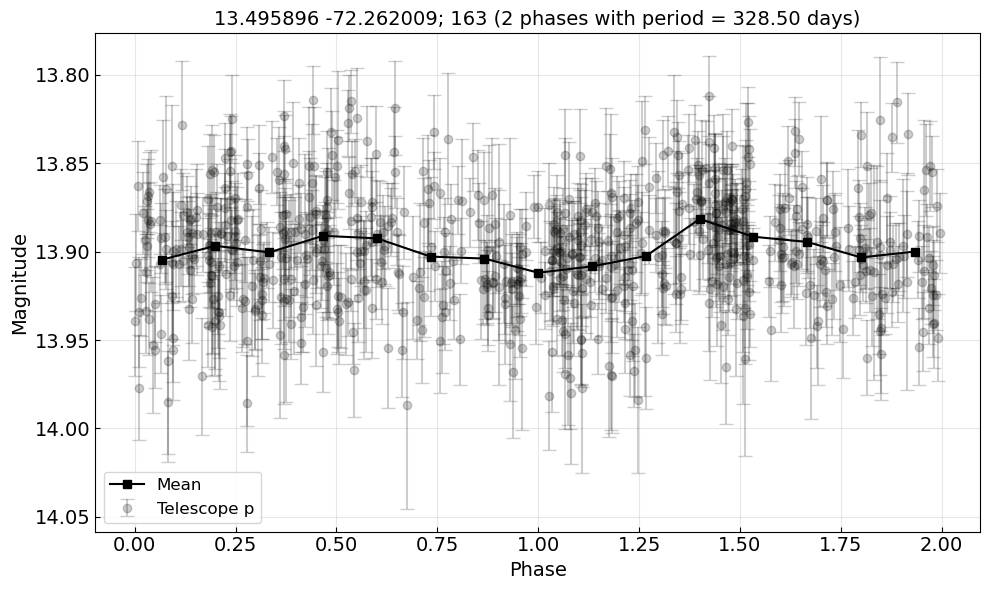

Average scatter (amplitude) per 10 point phase bin: 0.833 mJy
[0.00304418]
Amplitude metrics:
	Lower 5% percentile: 9.53 mJy, 13.84 mags
	Upper 5% percentile: 10.53 mJy, 13.95 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 1.00 mJy, 0.11 mags
Amplitude metrics:
	Lower 1% percentile: 9.34 mJy, 13.82 mags
	Upper 1% percentile: 10.72 mJy, 13.97 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.38 mJy, 0.15 mags
	Largest amplitude of variability (g-band: True): 1.61 mJy, 0.18 mags
	Average amplitude across all periods: 1.261 mJy
	Standard deviation of amplitudes: 0.186 mJy
	Average amplitude (1.261 mJy) is greater than 5 sigma (0.186 mJy). This indicates consistent variability across periods.
Star index: 231, Best period: 329.4691806268439


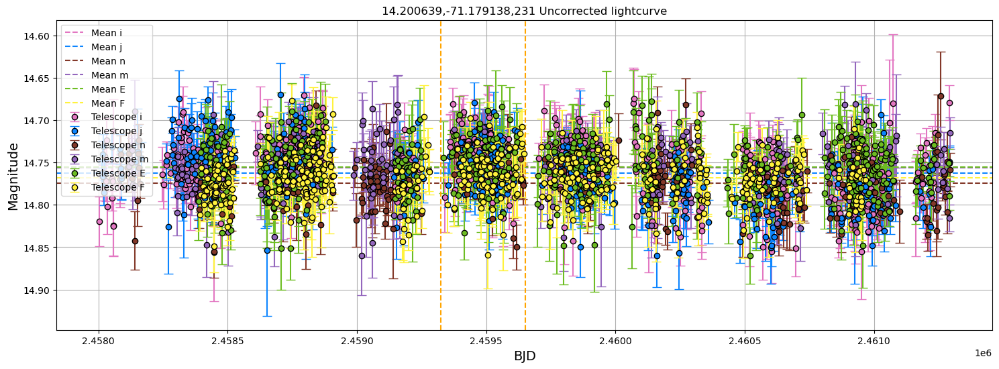

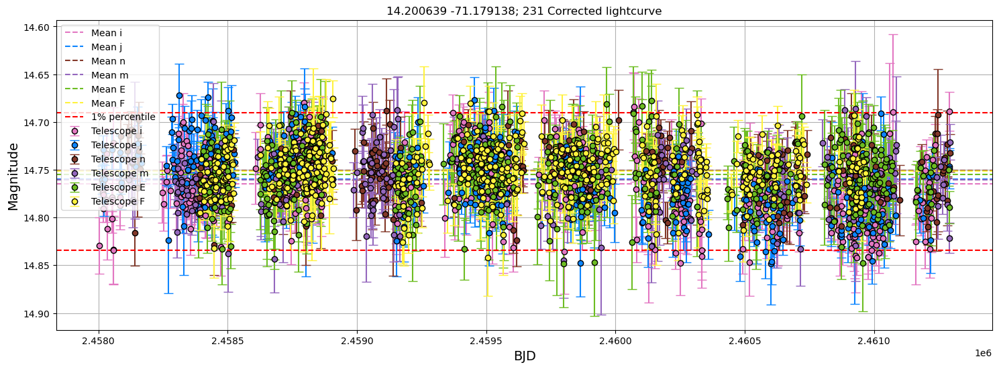

Best frequency: 0.003035 1/day, Best period: 329.47 days, Max power: 0.034, False alarm probability: 1.009e-14
False alarm level for 1.0%: 1.164e-02
Grid sampled at 22601 points


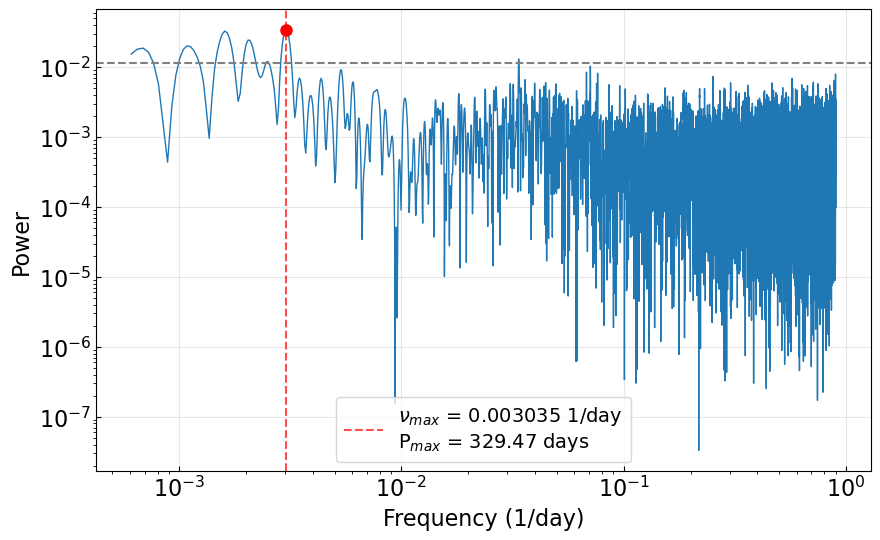

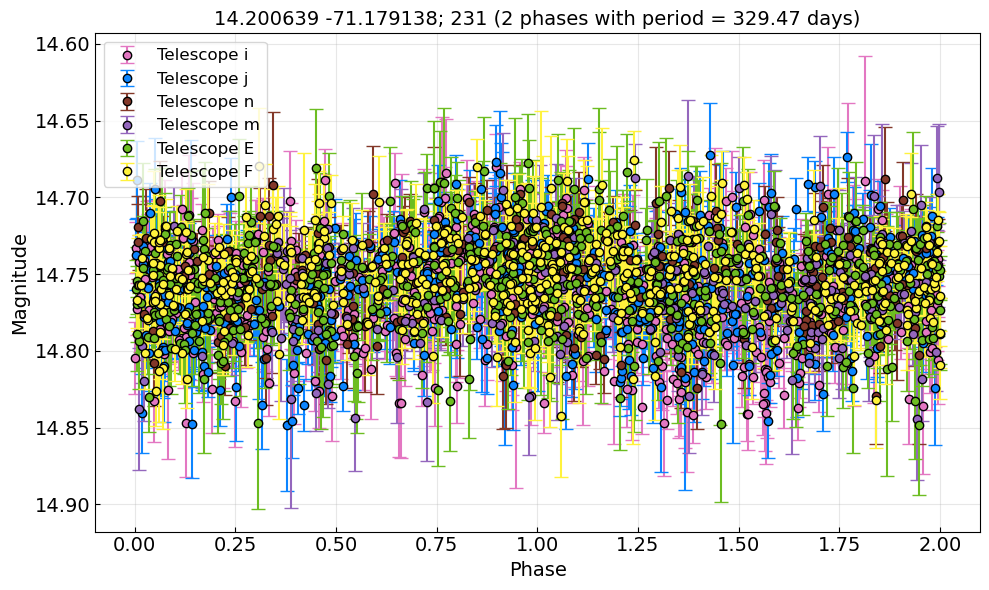

Average scatter (amplitude) per 10 point phase bin: 0.368 mJy


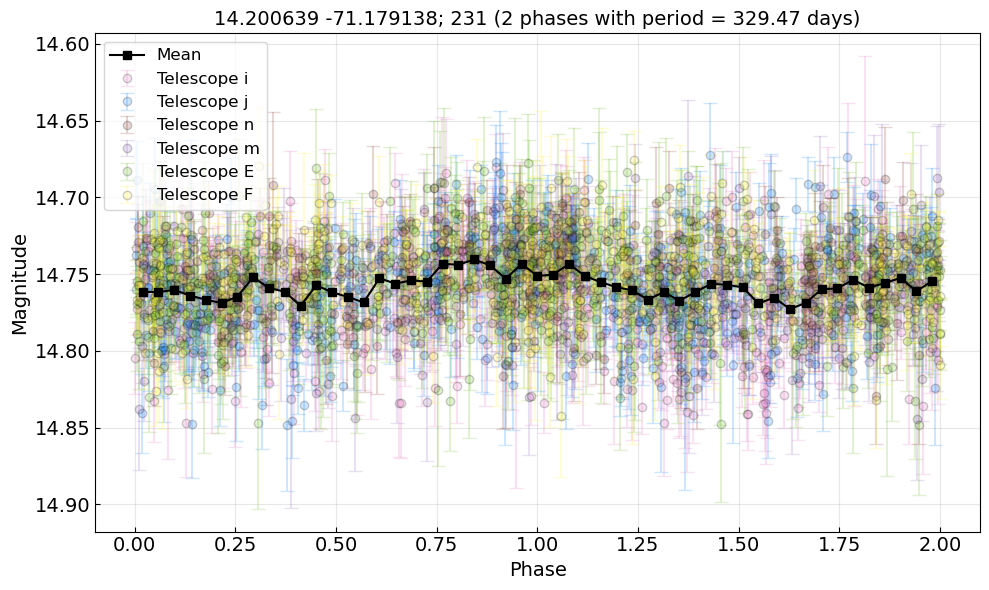

Average scatter (amplitude) per 10 point phase bin: 0.368 mJy
[0.00068721 0.00108518 0.00160252 0.00204028 0.00247804 0.00303519
 0.0336782 ]
Amplitude metrics:
	Lower 5% percentile: 4.32 mJy, 14.71 mags
	Upper 5% percentile: 4.75 mJy, 14.81 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 0.42 mJy, 0.10 mags
Amplitude metrics:
	Lower 1% percentile: 4.23 mJy, 14.69 mags
	Upper 1% percentile: 4.83 mJy, 14.83 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 0.60 mJy, 0.14 mags
	Largest amplitude of variability (g-band: True): 0.74 mJy, 0.18 mags
	Average amplitude across all periods: 0.664 mJy
	Standard deviation of amplitudes: 0.024 mJy
	Average amplitude (0.664 mJy) is greater than 5 sigma (0.024 mJy). This indicates consistent variability across periods.
Star index: 253, Best period: 328.00957920266893


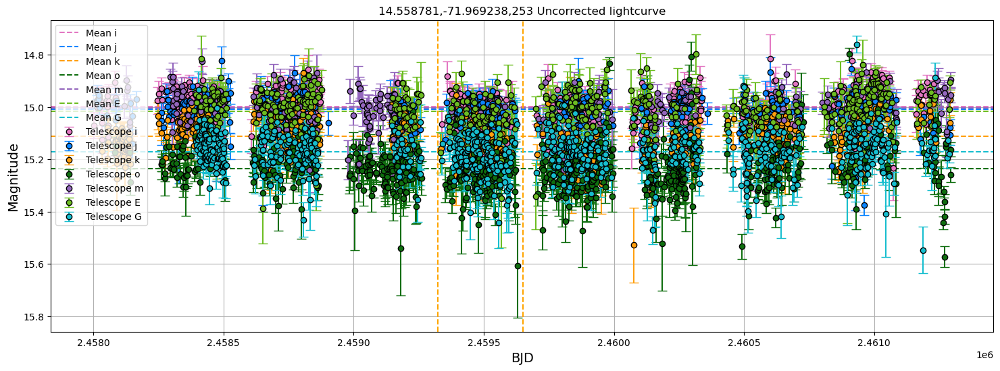

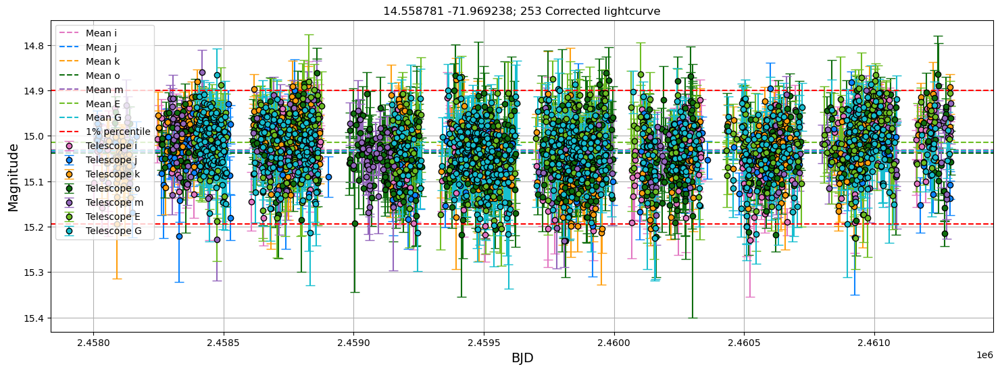

Best frequency: 0.003048 1/day, Best period: 328.08 days, Max power: 0.044, False alarm probability: 5.172e-33
False alarm level for 1.0%: 7.900e-03
Grid sampled at 34275 points


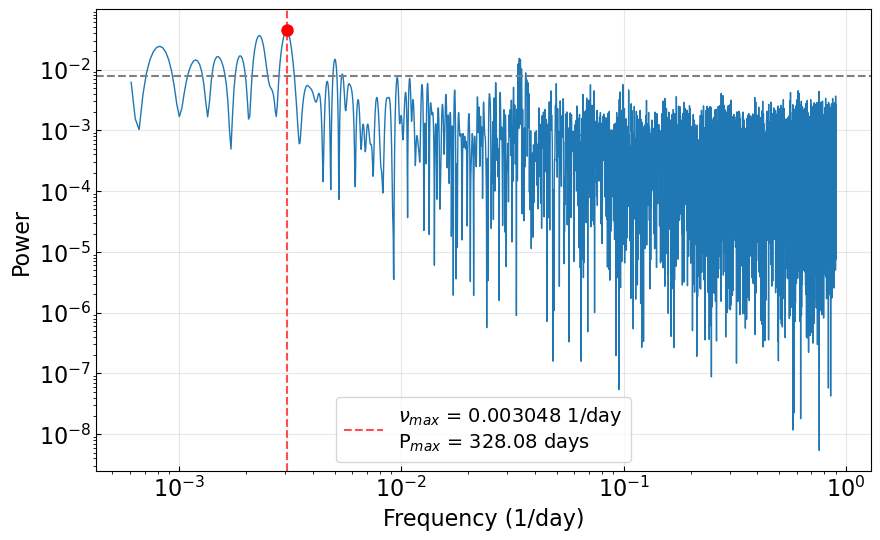

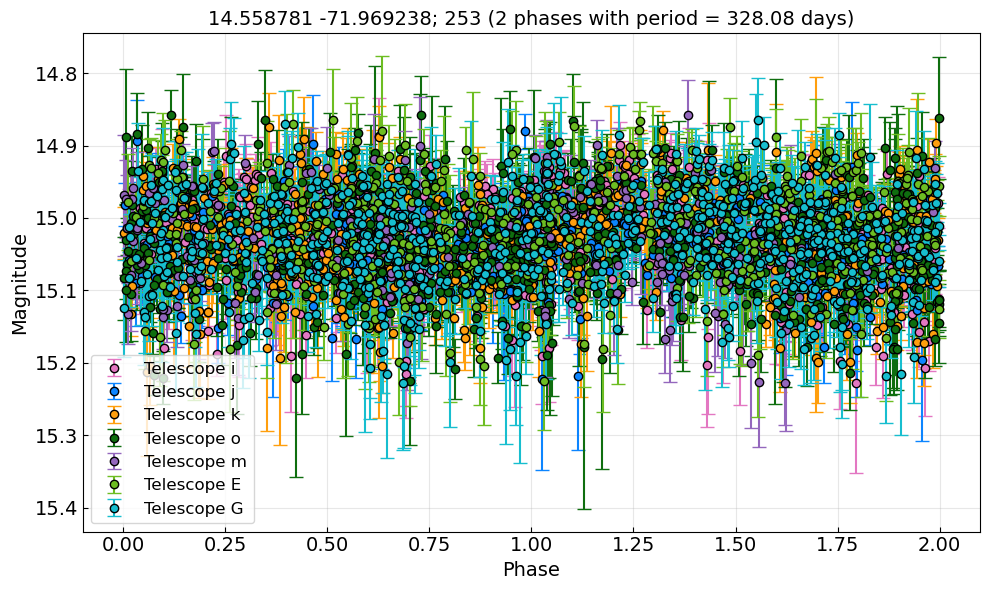

Average scatter (amplitude) per 10 point phase bin: 0.586 mJy


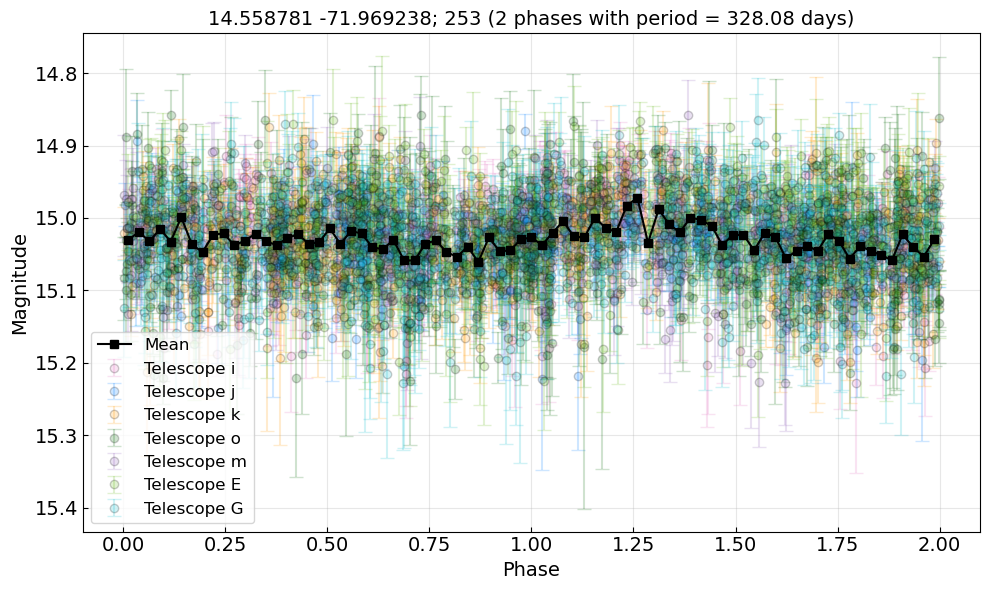

Average scatter (amplitude) per 10 point phase bin: 0.586 mJy
[0.00081754 0.00118492 0.00149982 0.00189344 0.00228705 0.00304805
 0.00501614 0.00540976 0.03351413 0.03390775 0.03430137 0.03469499
 0.03624322]
Amplitude metrics:
	Lower 5% percentile: 3.19 mJy, 14.93 mags
	Upper 5% percentile: 3.86 mJy, 15.14 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 0.67 mJy, 0.21 mags
Amplitude metrics:
	Lower 1% percentile: 3.04 mJy, 14.90 mags
	Upper 1% percentile: 3.98 mJy, 15.19 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 0.94 mJy, 0.29 mags
	Largest amplitude of variability (g-band: True): 1.20 mJy, 0.37 mags
	Average amplitude across all periods: 1.130 mJy
	Standard deviation of amplitudes: 0.063 mJy
	Average amplitude (1.130 mJy) is greater than 5 sigma (0.063 mJy). This indicates consistent variability across periods.
Star index: 264, Best period: 327.4933705150617


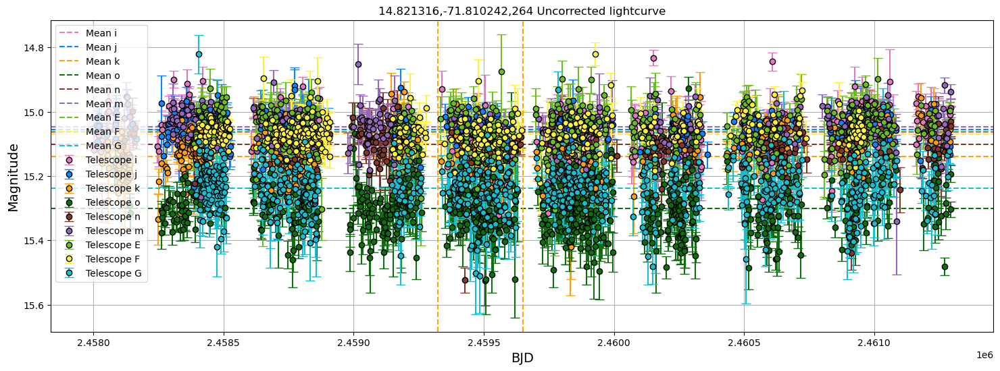

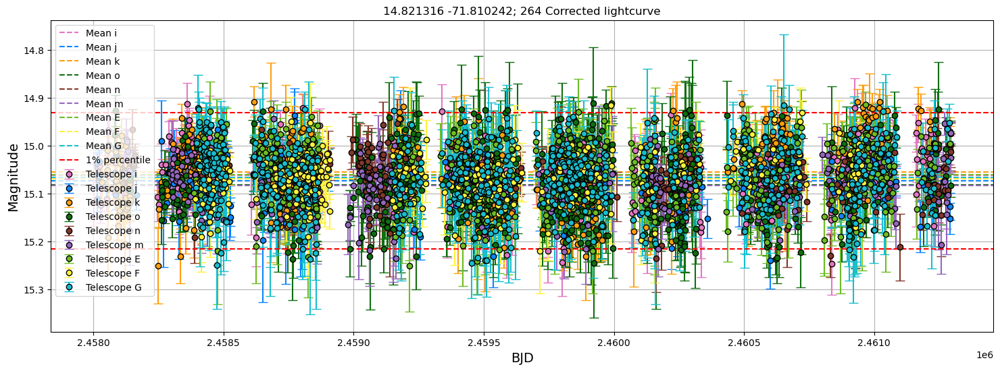

Best frequency: 0.003053 1/day, Best period: 327.55 days, Max power: 0.024, False alarm probability: 7.672e-19
False alarm level for 1.0%: 7.010e-03
Grid sampled at 38988 points


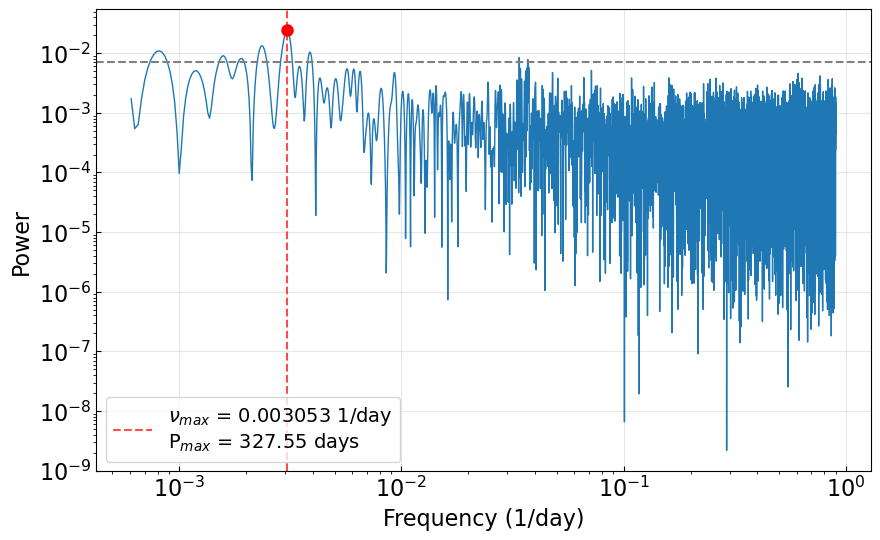

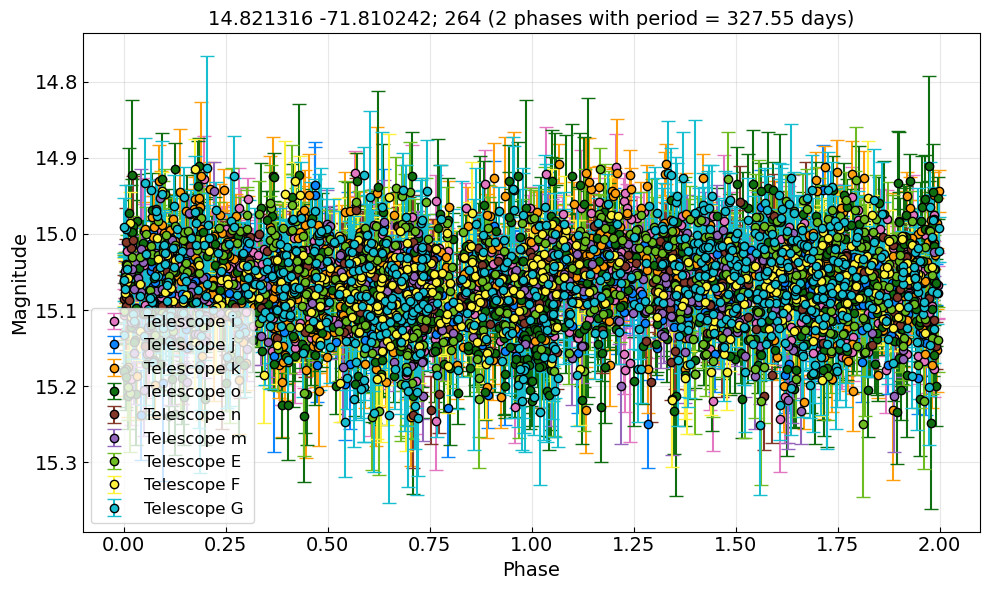

Average scatter (amplitude) per 10 point phase bin: 0.539 mJy


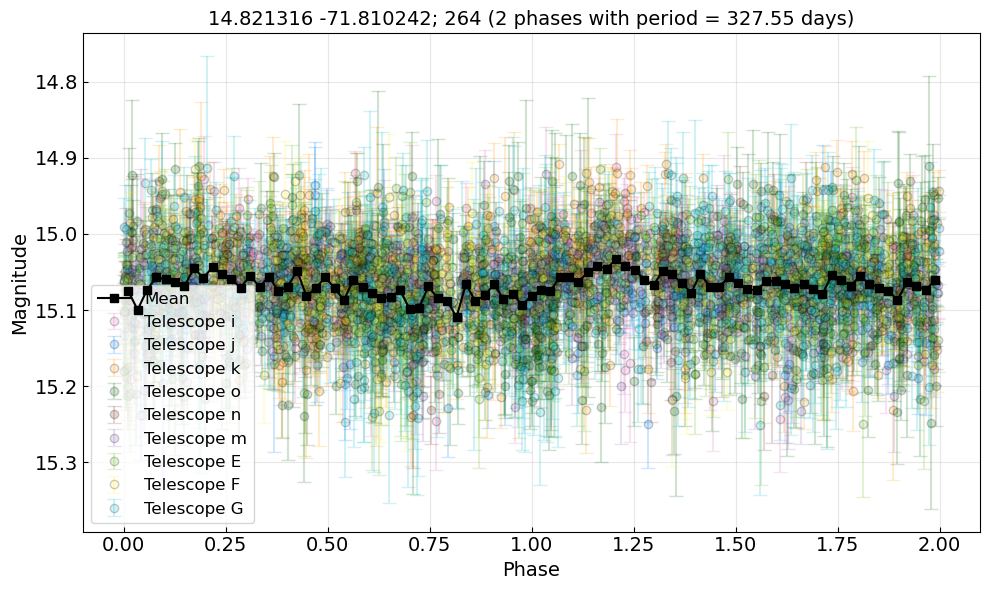

Average scatter (amplitude) per 10 point phase bin: 0.539 mJy
[0.00081524 0.00157651 0.00189948 0.00236086 0.00305293 0.00388342
 0.03389623 0.03703362]
Amplitude metrics:
	Lower 5% percentile: 3.10 mJy, 14.97 mags
	Upper 5% percentile: 3.72 mJy, 15.17 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 0.61 mJy, 0.20 mags
Amplitude metrics:
	Lower 1% percentile: 2.98 mJy, 14.93 mags
	Upper 1% percentile: 3.87 mJy, 15.21 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 0.89 mJy, 0.28 mags
	Largest amplitude of variability (g-band: True): 1.07 mJy, 0.34 mags
	Average amplitude across all periods: 1.016 mJy
	Standard deviation of amplitudes: 0.026 mJy
	Average amplitude (1.016 mJy) is greater than 5 sigma (0.026 mJy). This indicates consistent variability across periods.
Star index: 265, Best period: 328.99973450863416


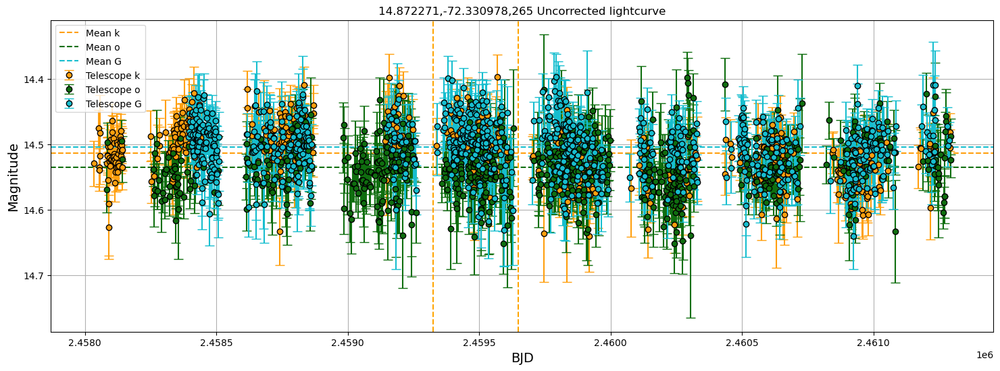

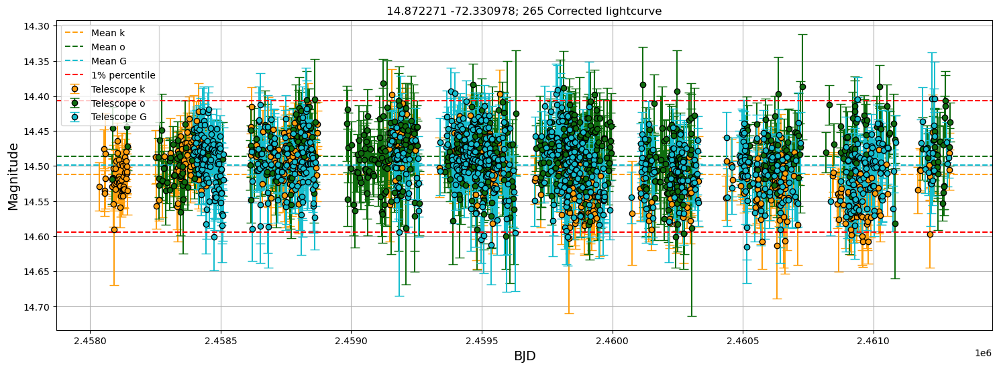

Best frequency: 0.003040 1/day, Best period: 329.00 days, Max power: 0.041, False alarm probability: 8.724e-15
False alarm level for 1.0%: 1.418e-02
Grid sampled at 18167 points


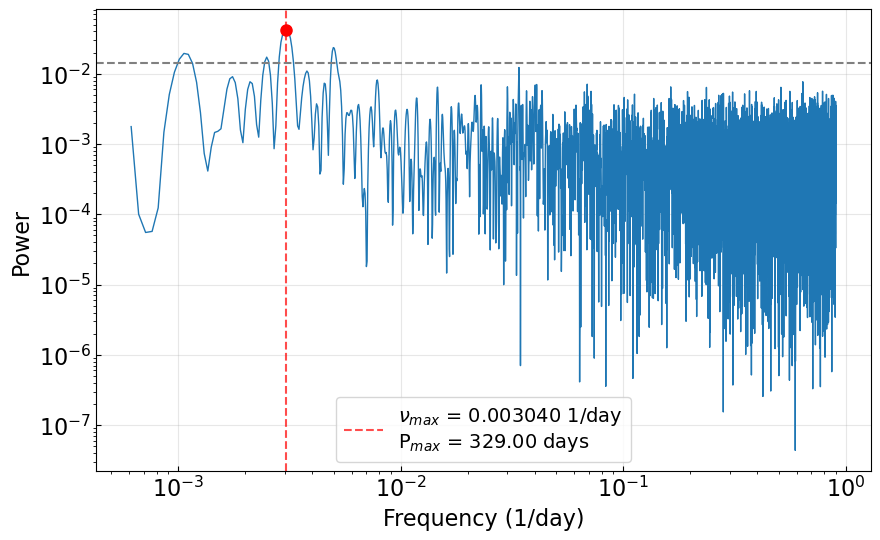

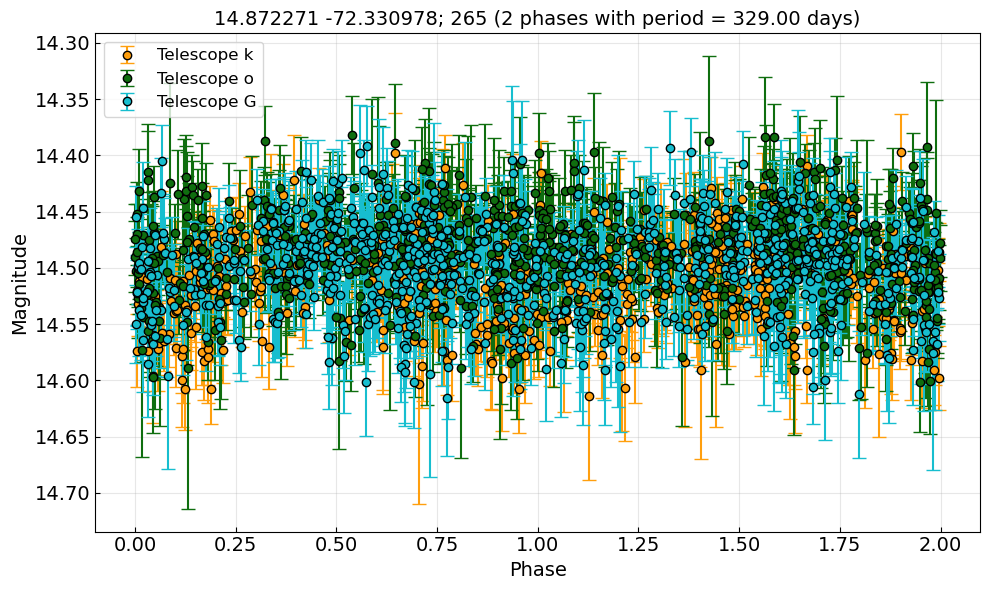

Average scatter (amplitude) per 10 point phase bin: 0.621 mJy


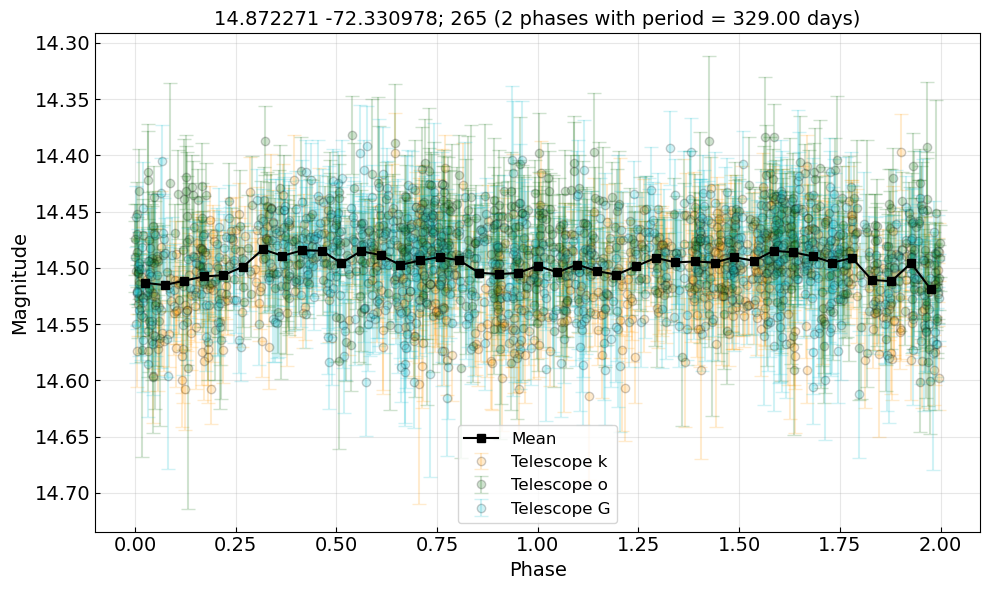

Average scatter (amplitude) per 10 point phase bin: 0.621 mJy
[0.00105914 0.00249491 0.00303952 0.00497038]
Amplitude metrics:
	Lower 5% percentile: 5.40 mJy, 14.43 mags
	Upper 5% percentile: 6.12 mJy, 14.57 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 0.72 mJy, 0.14 mags
Amplitude metrics:
	Lower 1% percentile: 5.28 mJy, 14.41 mags
	Upper 1% percentile: 6.27 mJy, 14.59 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 0.99 mJy, 0.19 mags
	Largest amplitude of variability (g-band: True): 1.24 mJy, 0.23 mags
	Average amplitude across all periods: 1.105 mJy
	Standard deviation of amplitudes: 0.097 mJy
	Average amplitude (1.105 mJy) is greater than 5 sigma (0.097 mJy). This indicates consistent variability across periods.


In [6]:
for star_idx in other_alias_320['star_idx'][10:20]:
    print(f"Star index: {star_idx}, Best period: {other_alias_320.loc[star_idx, 'best_period']}")
    info(star_idx)

Star index: 434, Best period: 384.4885015248704


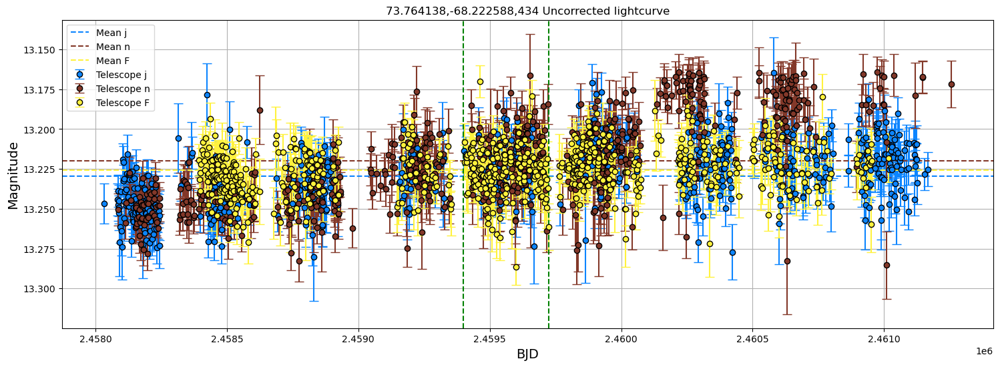

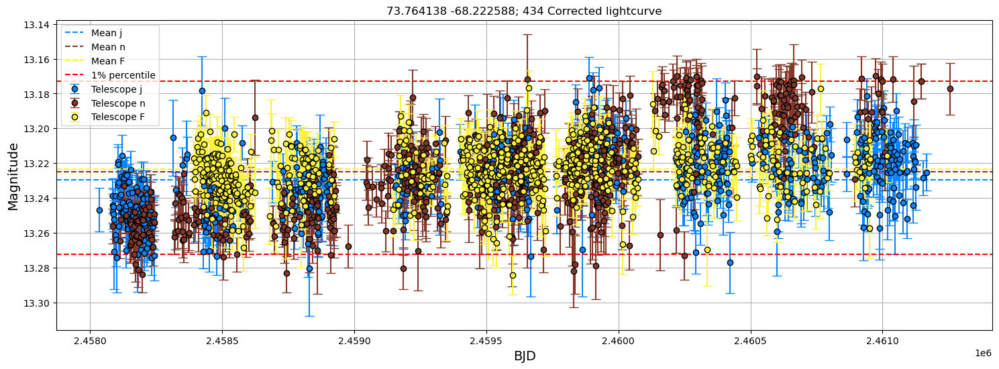

Best frequency: 0.002601 1/day, Best period: 384.49 days, Max power: 0.090, False alarm probability: 2.057e-36
False alarm level for 1.0%: 1.452e-02
Grid sampled at 17717 points


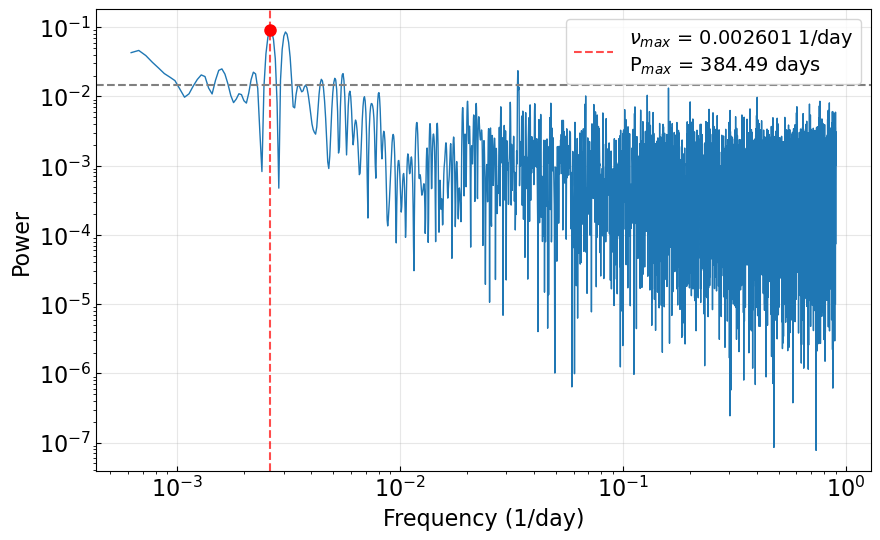

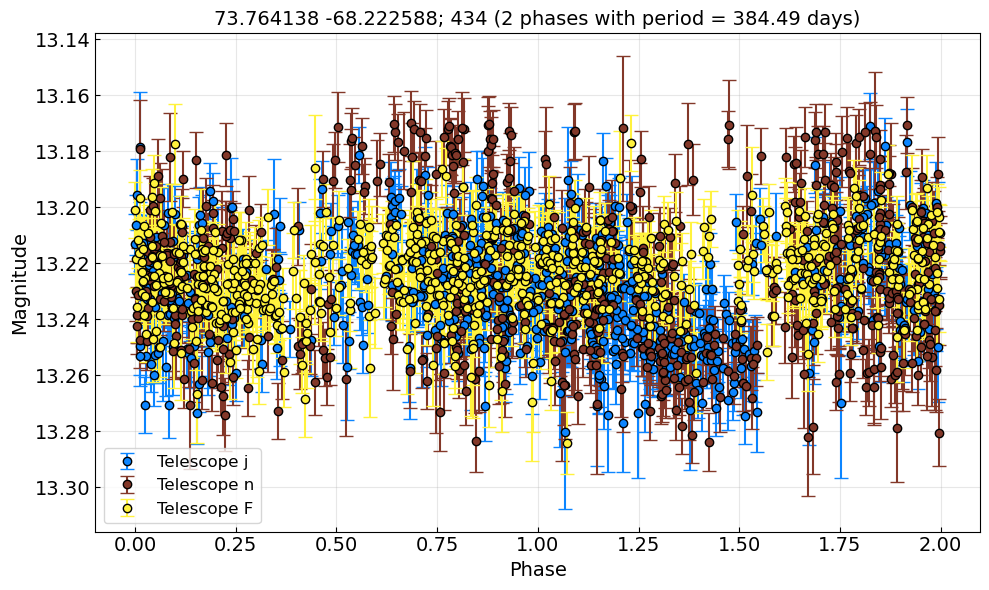

Average scatter (amplitude) per 10 point phase bin: 0.964 mJy


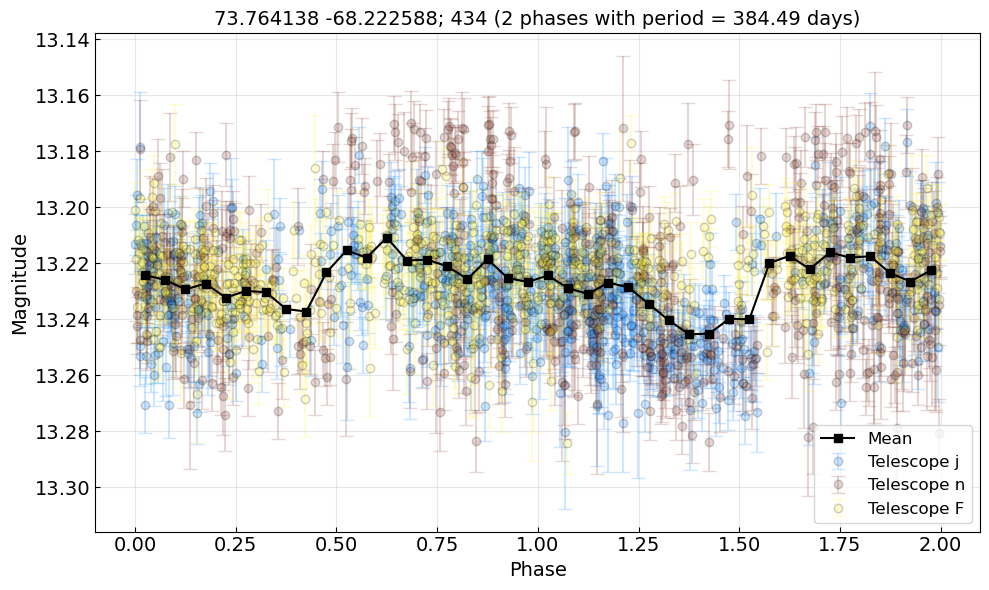

Average scatter (amplitude) per 10 point phase bin: 0.964 mJy
[0.00067173 0.00158553 0.00260086 0.00376849 0.00442845 0.00554531
 0.03372071]
Amplitude metrics:
	Lower 5% percentile: 18.04 mJy, 13.19 mags
	Upper 5% percentile: 19.25 mJy, 13.26 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 1.20 mJy, 0.07 mags
Amplitude metrics:
	Lower 1% percentile: 17.82 mJy, 13.17 mags
	Upper 1% percentile: 19.54 mJy, 13.27 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.71 mJy, 0.10 mags
	Largest amplitude of variability (g-band: True): 1.96 mJy, 0.11 mags
	Average amplitude across all periods: 1.651 mJy
	Standard deviation of amplitudes: 0.194 mJy
	Average amplitude (1.651 mJy) is greater than 5 sigma (0.194 mJy). This indicates consistent variability across periods.
Star index: 439, Best period: 380.41384283663064


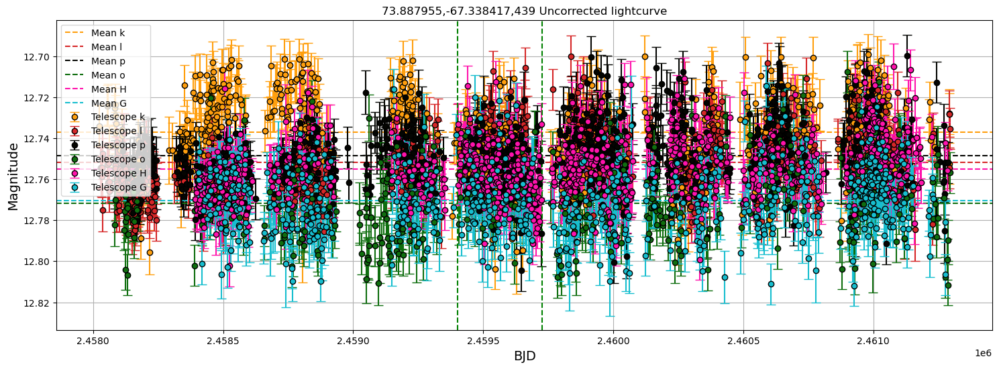

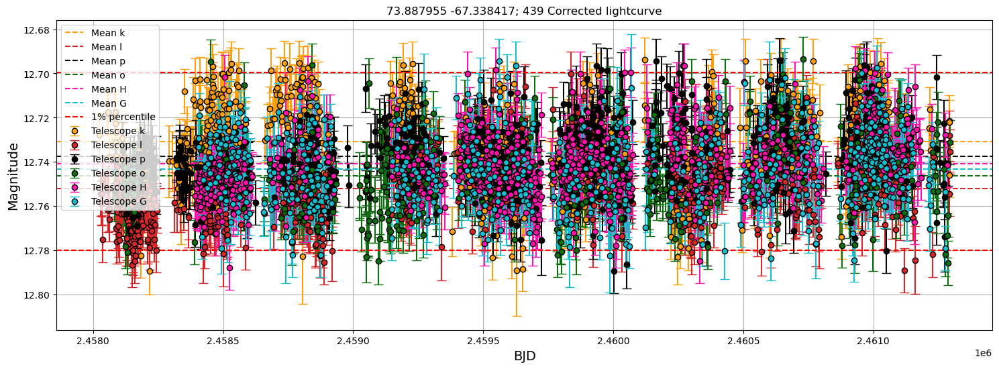

Best frequency: 0.002628 1/day, Best period: 380.49 days, Max power: 0.042, False alarm probability: 1.589e-33
False alarm level for 1.0%: 7.464e-03
Grid sampled at 36569 points


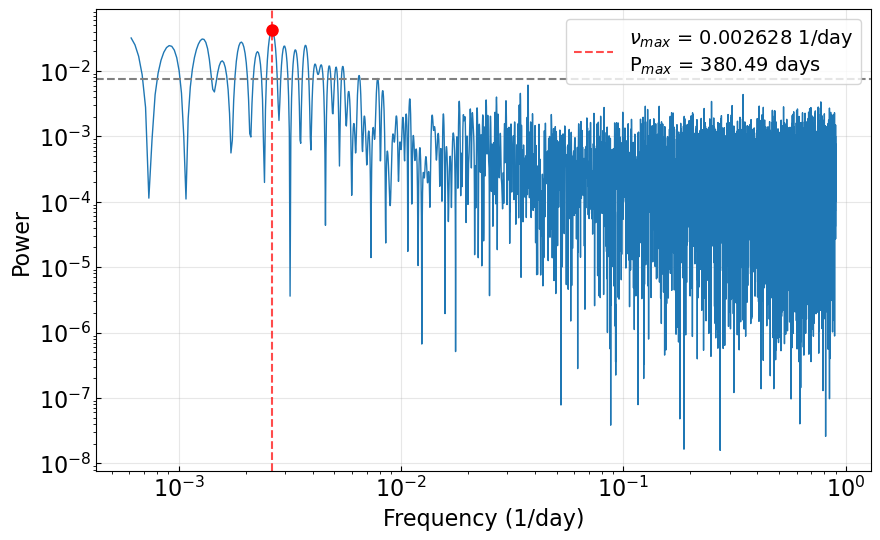

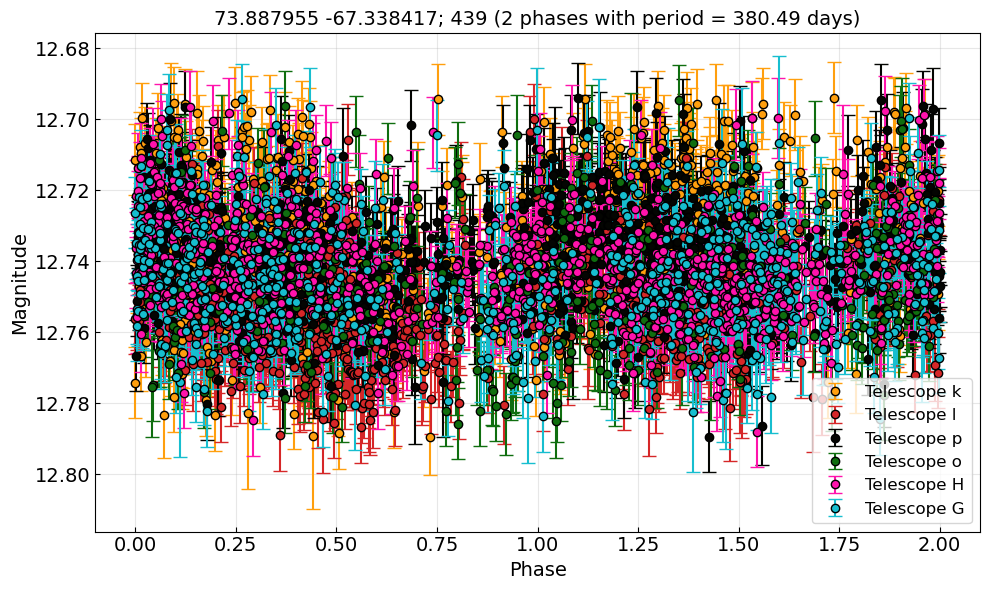

Average scatter (amplitude) per 10 point phase bin: 1.297 mJy


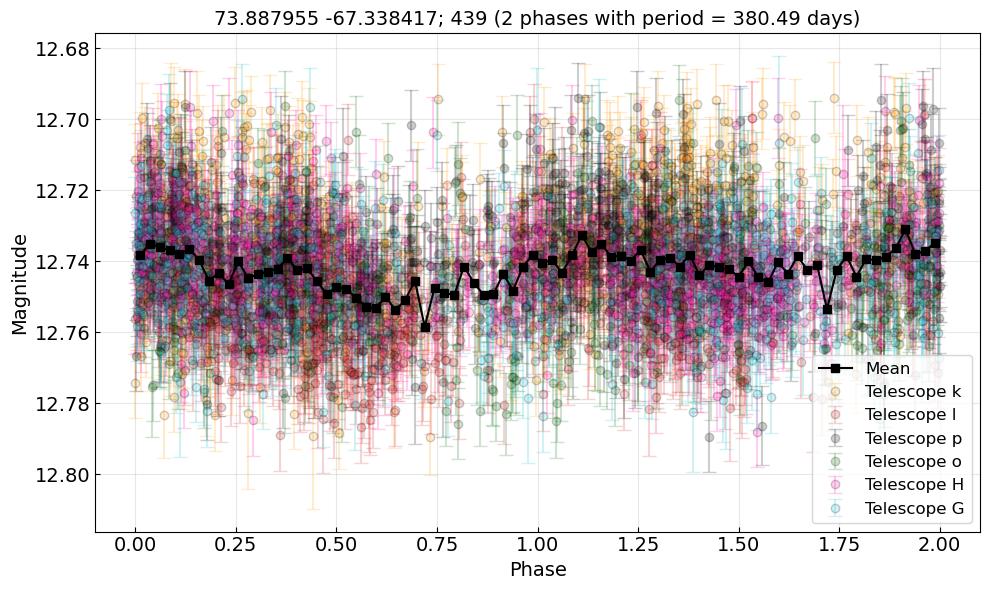

Average scatter (amplitude) per 10 point phase bin: 1.297 mJy
[0.00090657 0.0012755  0.00157064 0.00191497 0.0022593  0.00262822
 0.00299714 0.00334147 0.0037104  0.00410392 0.00437446 0.00474339
 0.00511231 0.00545664 0.00646503 0.00784235]
Amplitude metrics:
	Lower 5% percentile: 28.34 mJy, 12.71 mags
	Upper 5% percentile: 29.89 mJy, 12.77 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 1.55 mJy, 0.06 mags
Amplitude metrics:
	Lower 1% percentile: 28.06 mJy, 12.70 mags
	Upper 1% percentile: 30.21 mJy, 12.78 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 2.16 mJy, 0.08 mags
	Largest amplitude of variability (g-band: True): 2.57 mJy, 0.10 mags
	Average amplitude across all periods: 2.470 mJy
	Standard deviation of amplitudes: 0.057 mJy
	Average amplitude (2.470 mJy) is greater than 5 sigma (0.057 mJy). This indicates consistent variability across periods.
Star index: 44

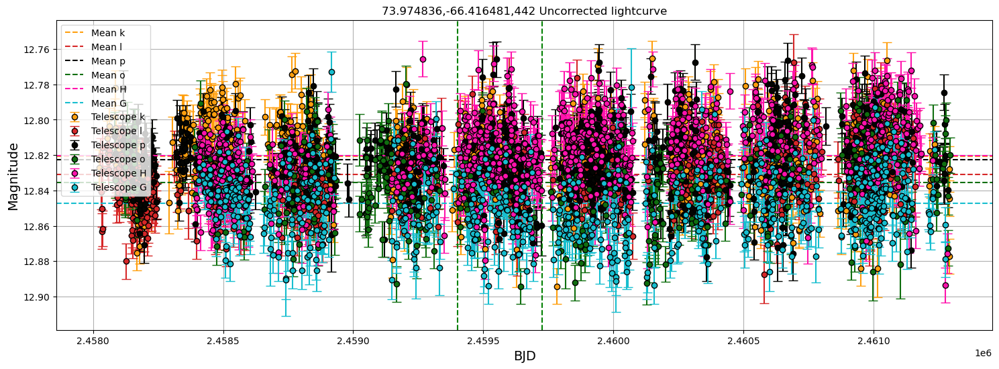

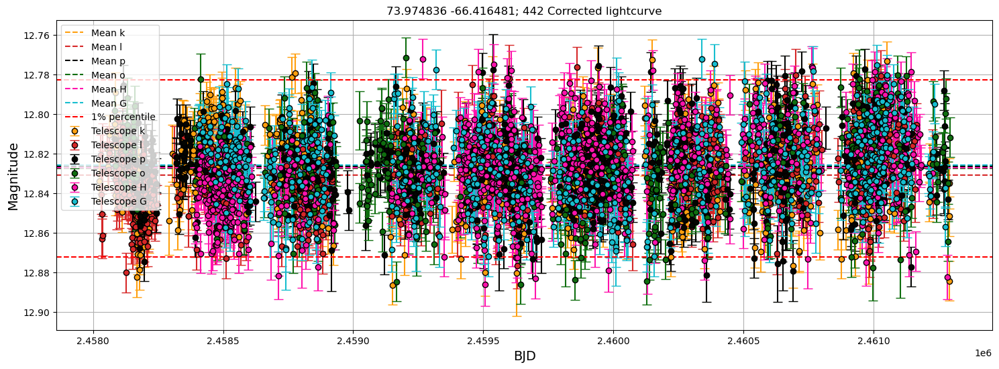

Best frequency: 0.002621 1/day, Best period: 381.50 days, Max power: 0.026, False alarm probability: 5.349e-19
False alarm level for 1.0%: 7.355e-03
Grid sampled at 37144 points


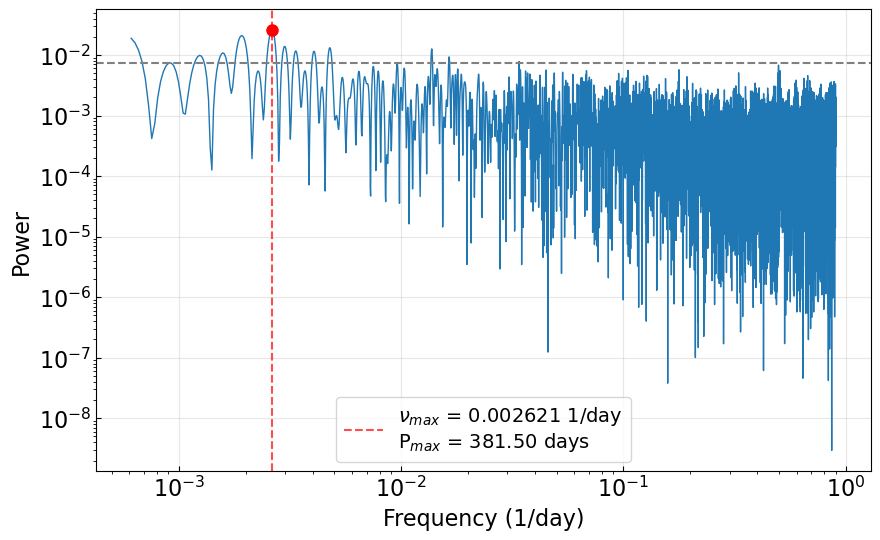

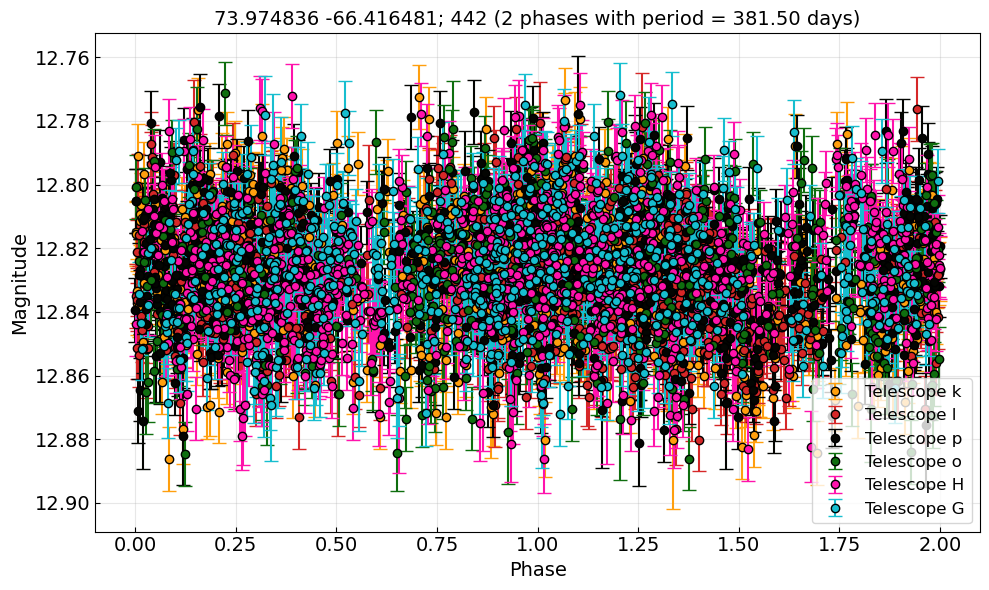

Average scatter (amplitude) per 10 point phase bin: 1.312 mJy


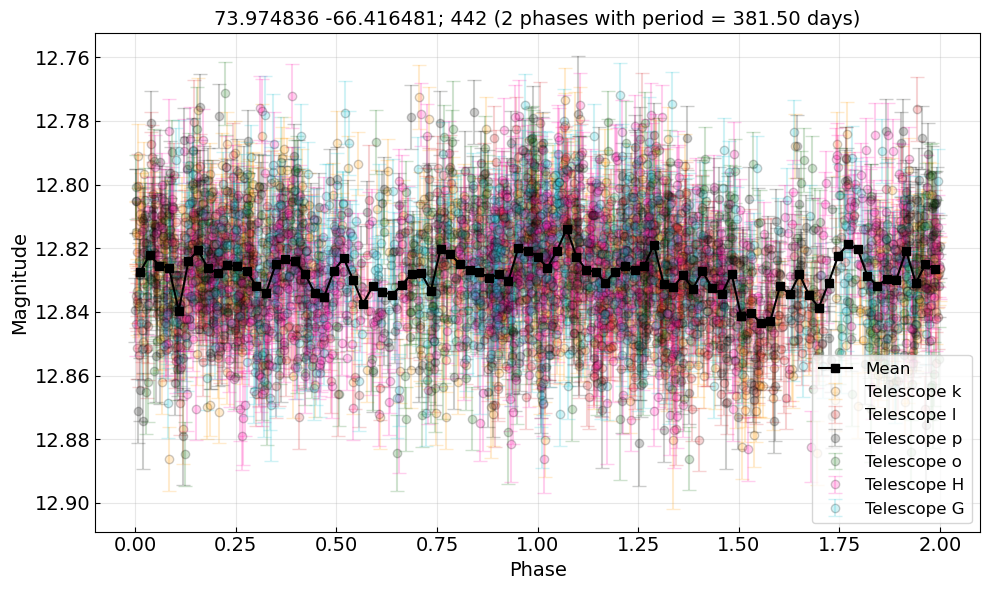

Average scatter (amplitude) per 10 point phase bin: 1.312 mJy
[0.00092627 0.00124105 0.00158005 0.00191905 0.00262126 0.00300869
 0.00337191 0.0040499  0.00477633 0.01373559 0.01644758 0.03390603]
Amplitude metrics:
	Lower 5% percentile: 26.07 mJy, 12.80 mags
	Upper 5% percentile: 27.66 mJy, 12.86 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 1.59 mJy, 0.06 mags
Amplitude metrics:
	Lower 1% percentile: 25.77 mJy, 12.78 mags
	Upper 1% percentile: 27.99 mJy, 12.87 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 2.21 mJy, 0.09 mags
	Largest amplitude of variability (g-band: True): 2.84 mJy, 0.11 mags
	Average amplitude across all periods: 2.640 mJy
	Standard deviation of amplitudes: 0.154 mJy
	Average amplitude (2.640 mJy) is greater than 5 sigma (0.154 mJy). This indicates consistent variability across periods.
Star index: 451, Best period: 382.8446078626384


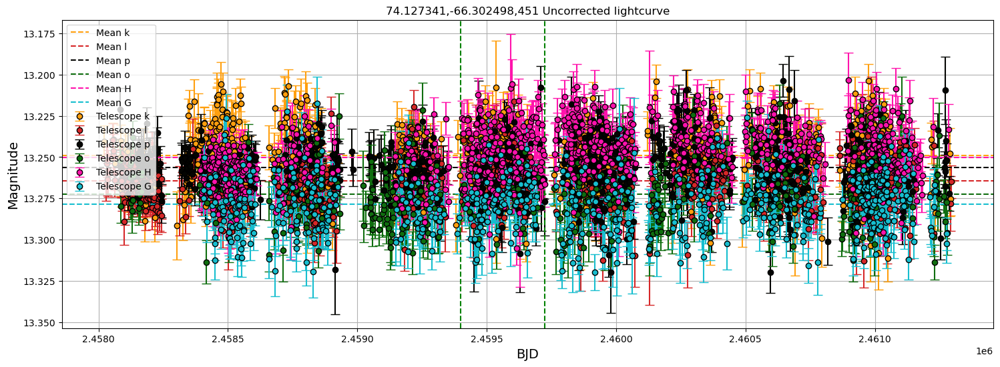

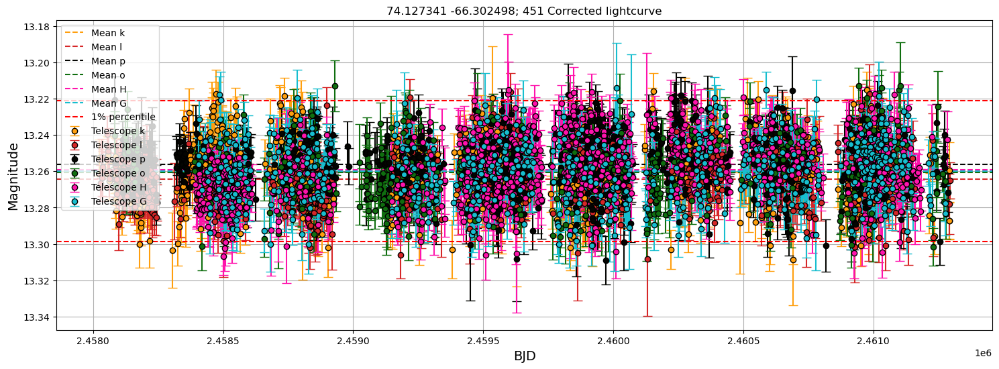

Best frequency: 0.002612 1/day, Best period: 382.84 days, Max power: 0.021, False alarm probability: 2.014e-14
False alarm level for 1.0%: 7.407e-03
Grid sampled at 36865 points


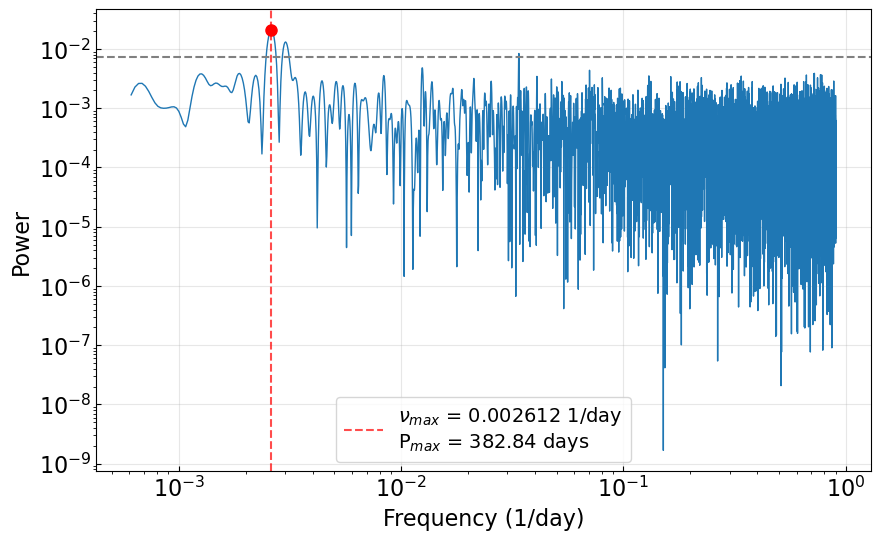

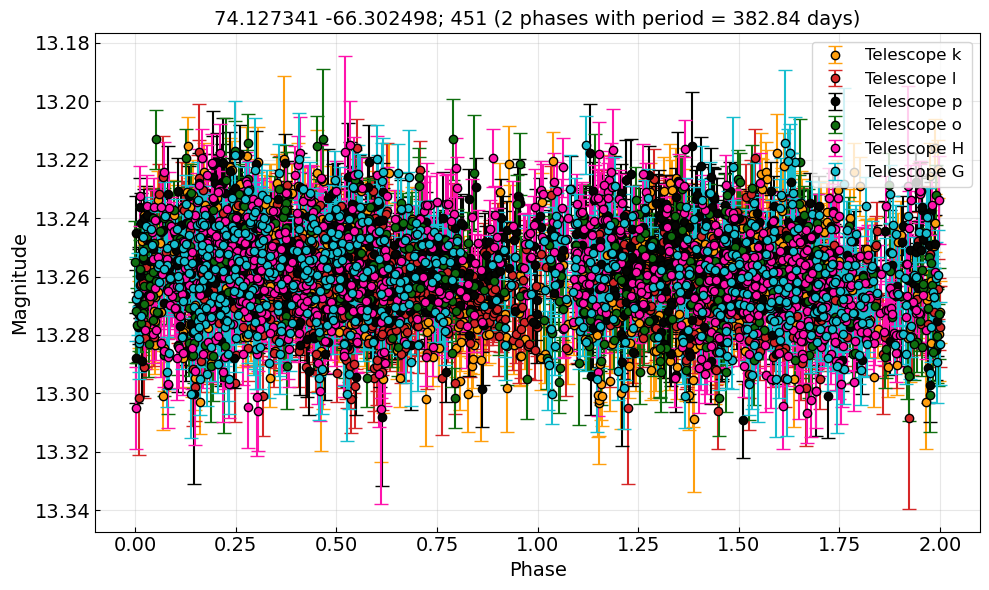

Average scatter (amplitude) per 10 point phase bin: 0.788 mJy


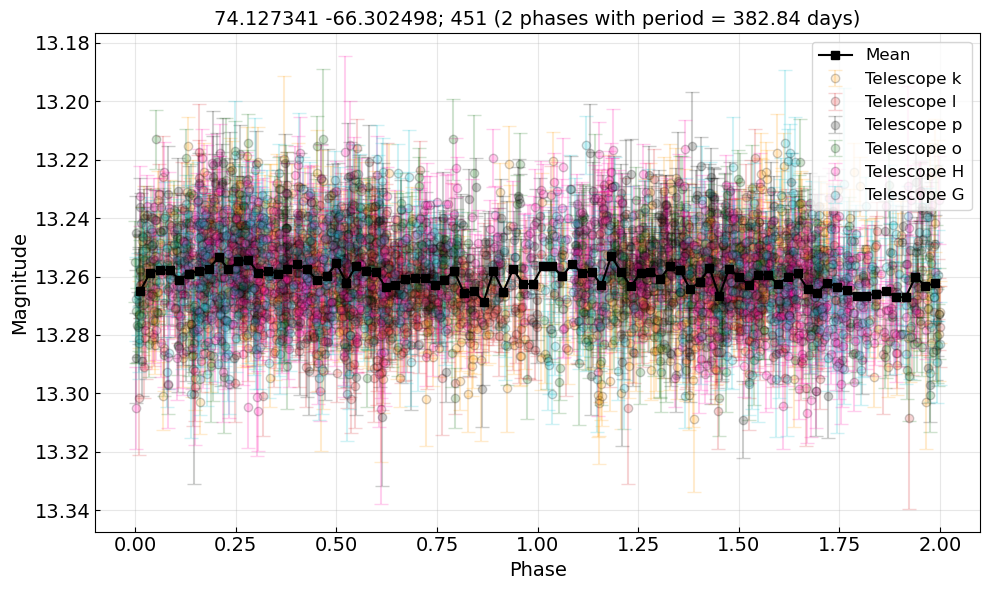

Average scatter (amplitude) per 10 point phase bin: 0.788 mJy
[0.00261203 0.00302678 0.0338408 ]
Amplitude metrics:
	Lower 5% percentile: 17.59 mJy, 13.23 mags
	Upper 5% percentile: 18.50 mJy, 13.29 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 0.91 mJy, 0.05 mags
Amplitude metrics:
	Lower 1% percentile: 17.40 mJy, 13.22 mags
	Upper 1% percentile: 18.69 mJy, 13.30 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.29 mJy, 0.08 mags
	Largest amplitude of variability (g-band: True): 1.60 mJy, 0.10 mags
	Average amplitude across all periods: 1.502 mJy
	Standard deviation of amplitudes: 0.054 mJy
	Average amplitude (1.502 mJy) is greater than 5 sigma (0.054 mJy). This indicates consistent variability across periods.
Star index: 452, Best period: 377.4576660598583


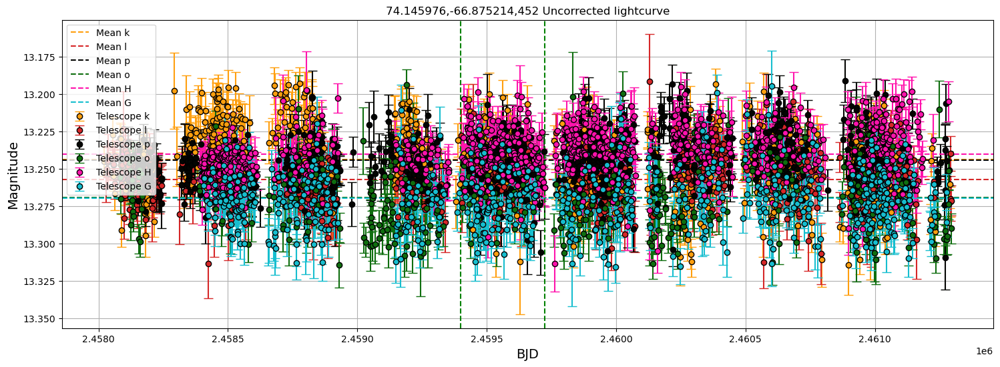

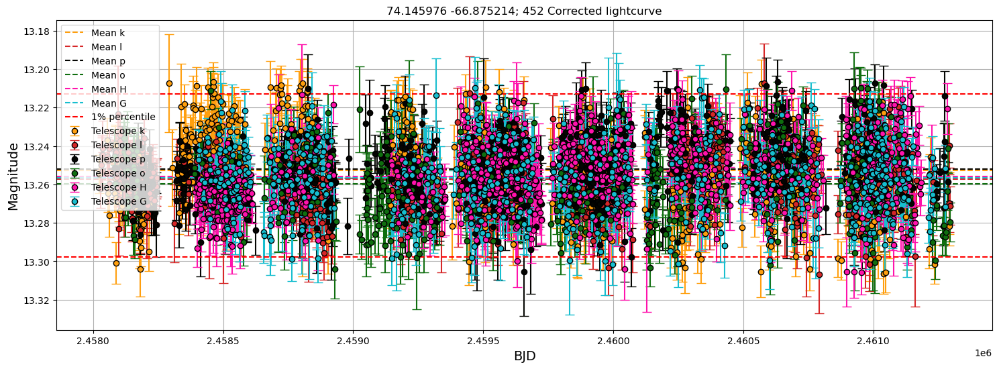

Best frequency: 0.002649 1/day, Best period: 377.46 days, Max power: 0.016, False alarm probability: 4.315e-10
False alarm level for 1.0%: 7.452e-03
Grid sampled at 36632 points


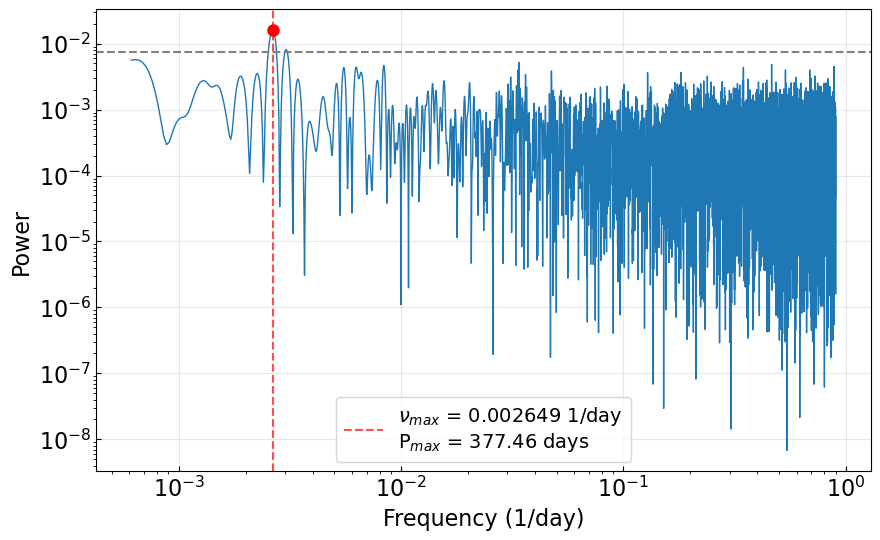

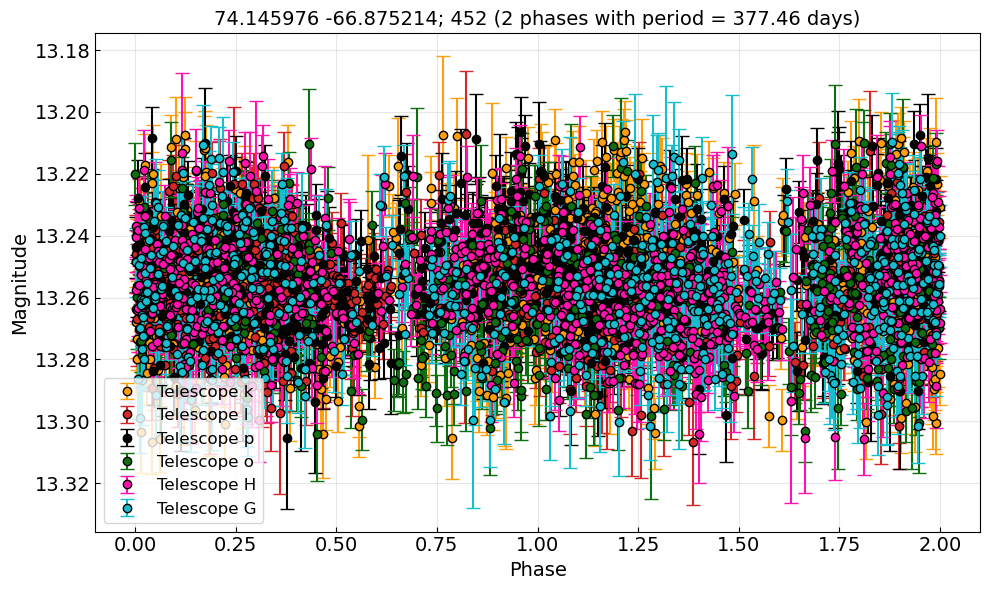

Average scatter (amplitude) per 10 point phase bin: 0.842 mJy


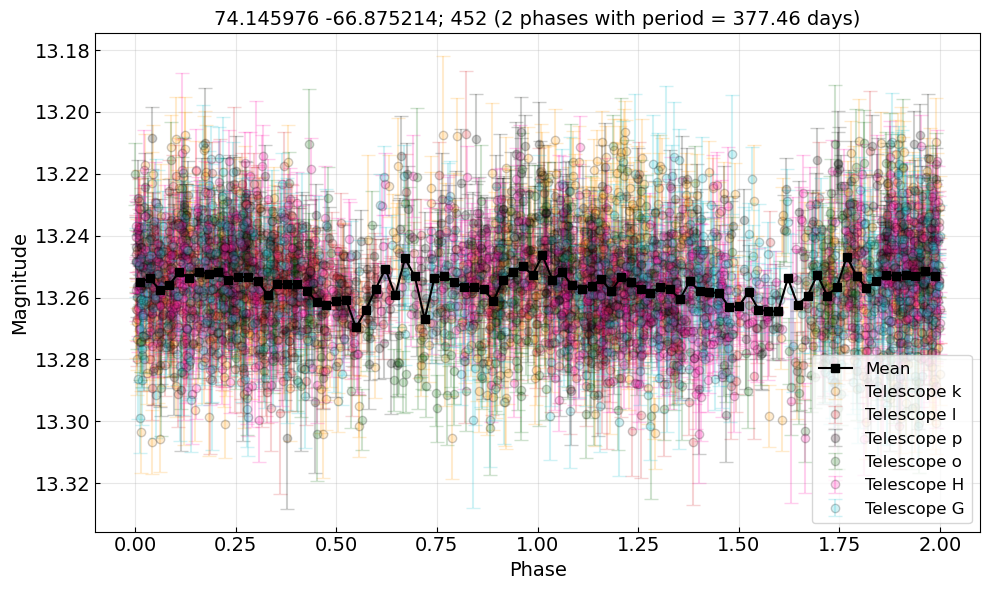

Average scatter (amplitude) per 10 point phase bin: 0.842 mJy
[0.0026493  0.00304215]
Amplitude metrics:
	Lower 5% percentile: 17.62 mJy, 13.22 mags
	Upper 5% percentile: 18.63 mJy, 13.29 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 1.01 mJy, 0.06 mags
Amplitude metrics:
	Lower 1% percentile: 17.42 mJy, 13.21 mags
	Upper 1% percentile: 18.83 mJy, 13.30 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.41 mJy, 0.08 mags
	Largest amplitude of variability (g-band: True): 1.67 mJy, 0.10 mags
	Average amplitude across all periods: 1.579 mJy
	Standard deviation of amplitudes: 0.064 mJy
	Average amplitude (1.579 mJy) is greater than 5 sigma (0.064 mJy). This indicates consistent variability across periods.
Star index: 456, Best period: 380.30746290666616


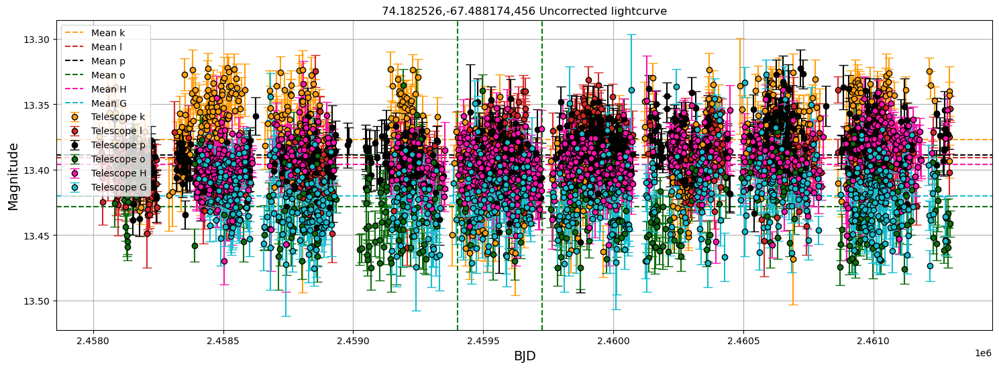

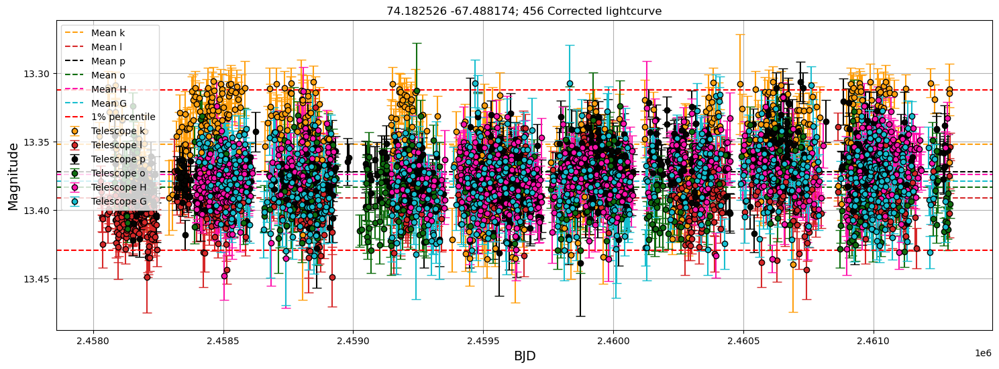

Best frequency: 0.002630 1/day, Best period: 380.23 days, Max power: 0.023, False alarm probability: 1.471e-16
False alarm level for 1.0%: 7.554e-03
Grid sampled at 36092 points


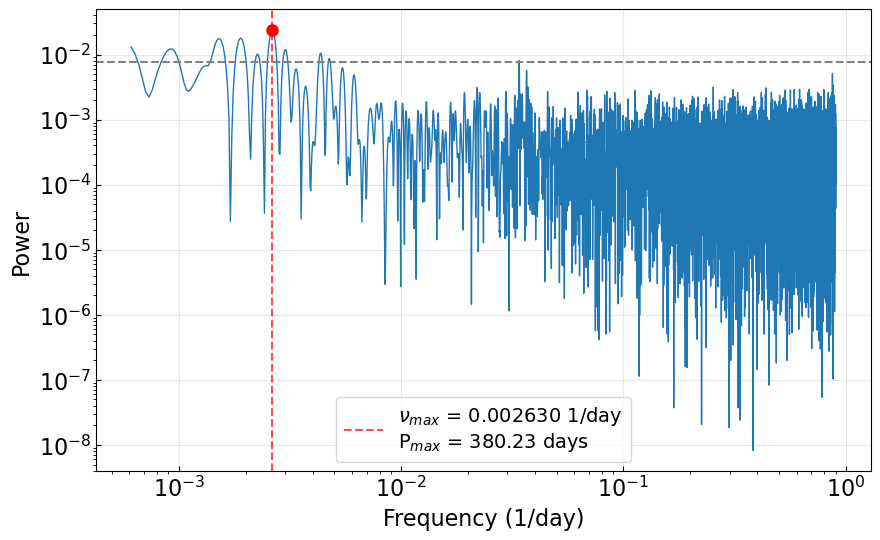

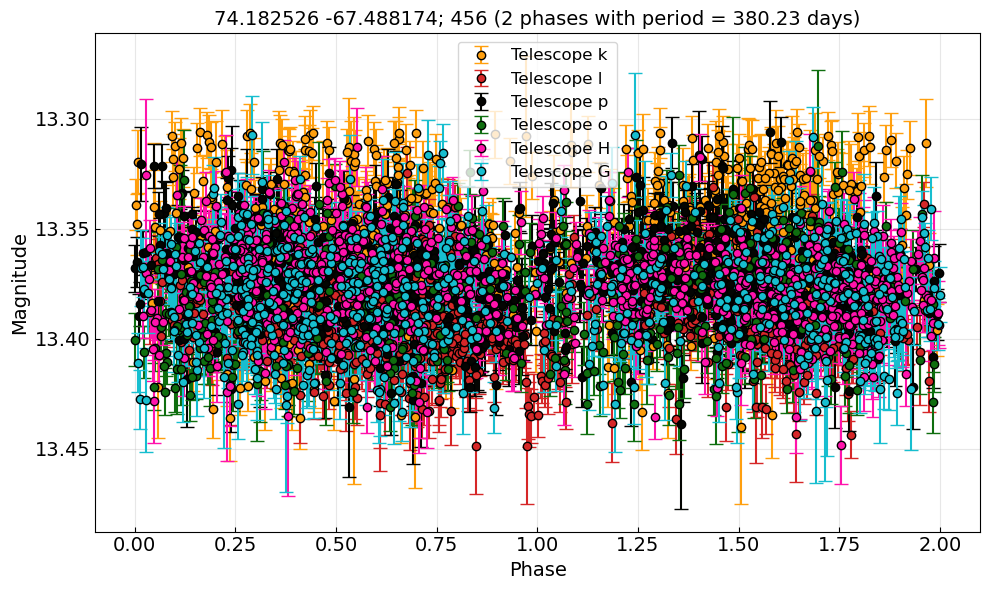

Average scatter (amplitude) per 10 point phase bin: 1.095 mJy


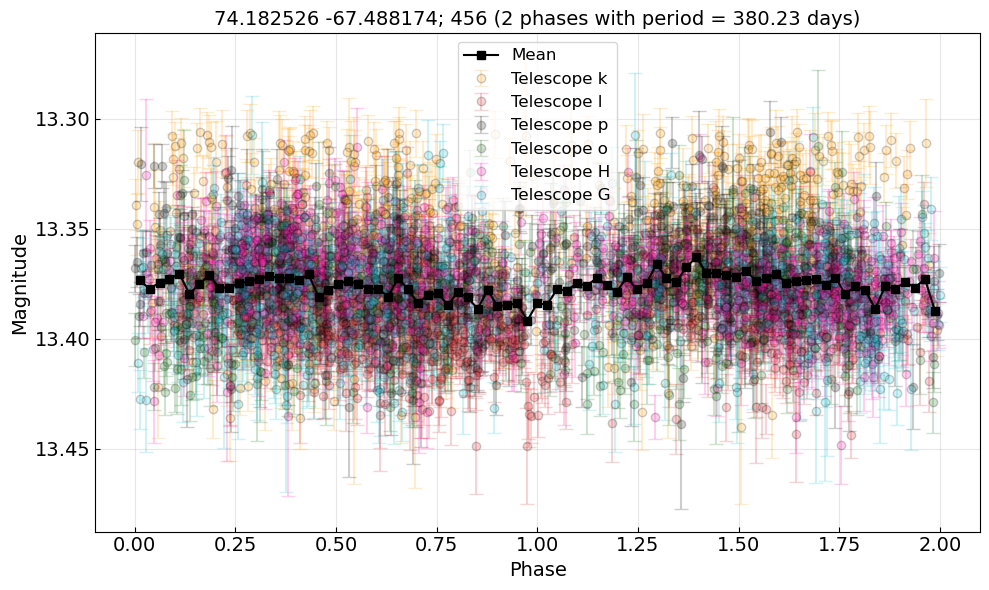

Average scatter (amplitude) per 10 point phase bin: 1.095 mJy
[0.00091047 0.00150855 0.00190727 0.00225615 0.00262995 0.00300376
 0.00434944 0.00474816 0.03395442]
Amplitude metrics:
	Lower 5% percentile: 15.65 mJy, 13.33 mags
	Upper 5% percentile: 16.90 mJy, 13.41 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 1.25 mJy, 0.08 mags
Amplitude metrics:
	Lower 1% percentile: 15.43 mJy, 13.31 mags
	Upper 1% percentile: 17.19 mJy, 13.43 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.76 mJy, 0.12 mags
	Largest amplitude of variability (g-band: True): 2.13 mJy, 0.14 mags
	Average amplitude across all periods: 1.979 mJy
	Standard deviation of amplitudes: 0.099 mJy
	Average amplitude (1.979 mJy) is greater than 5 sigma (0.099 mJy). This indicates consistent variability across periods.
Star index: 457, Best period: 378.855366684587


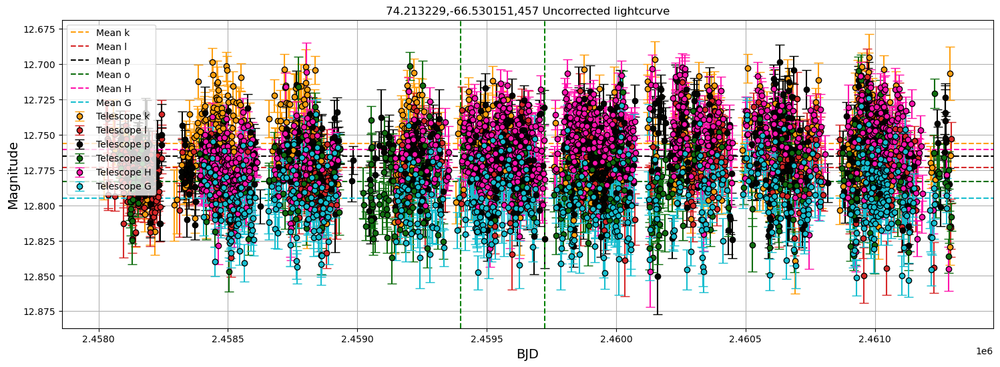

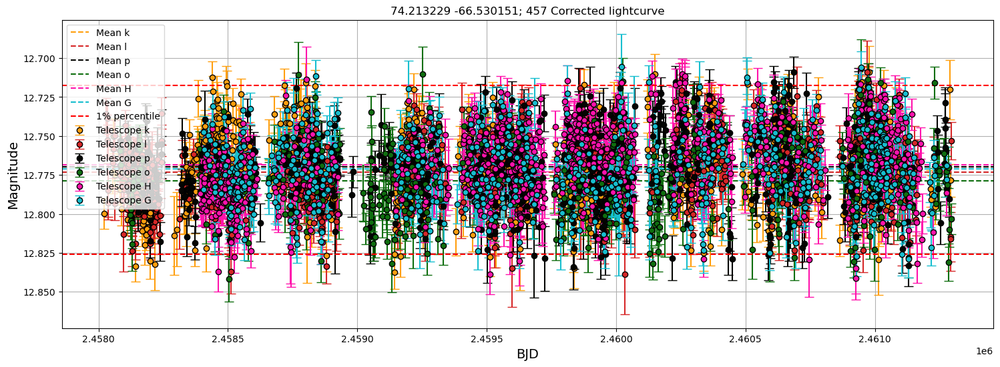

Best frequency: 0.002640 1/day, Best period: 378.86 days, Max power: 0.027, False alarm probability: 1.558e-20
False alarm level for 1.0%: 7.326e-03
Grid sampled at 37252 points


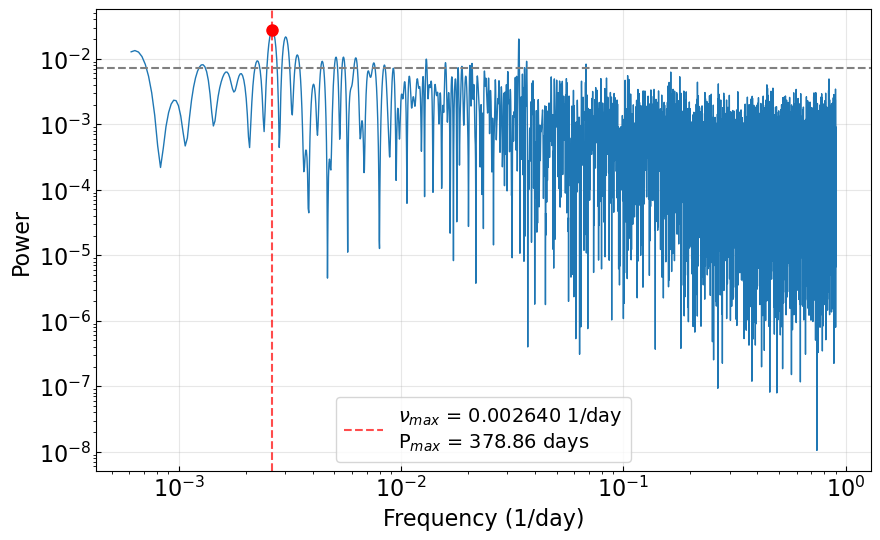

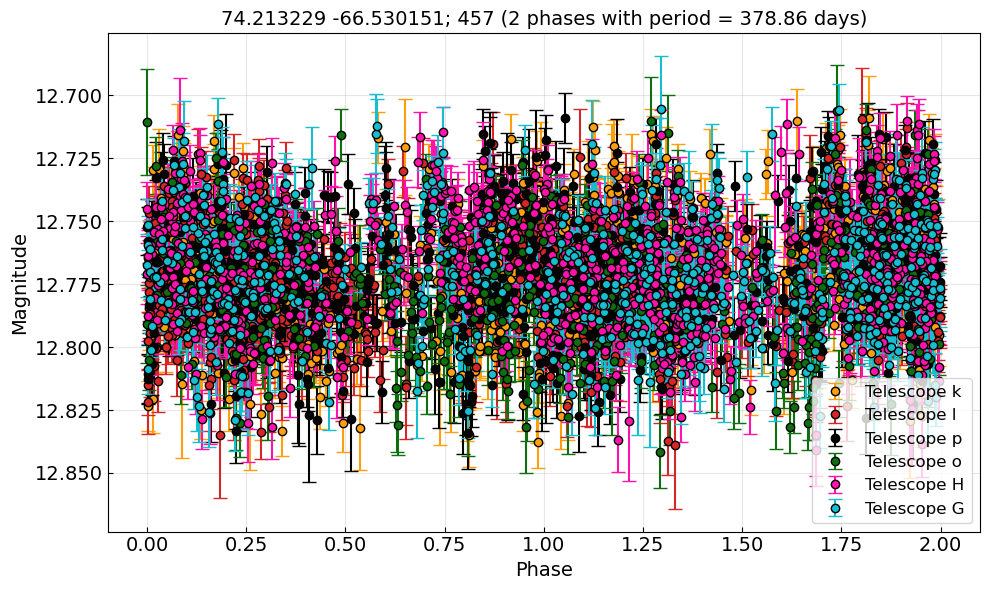

Average scatter (amplitude) per 10 point phase bin: 1.620 mJy


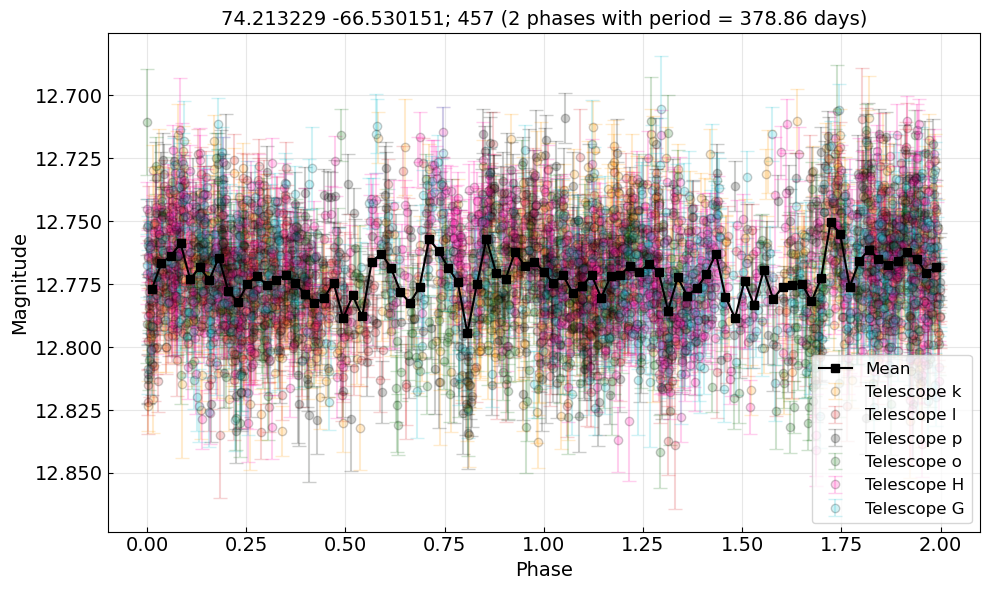

Average scatter (amplitude) per 10 point phase bin: 1.620 mJy
[0.00063558 0.00128747 0.00225323 0.00263953 0.00302583 0.00341214
 0.00442619 0.00510222 0.00551267 0.00626113 0.00754076 0.00840995
 0.01299731 0.0158463  0.01876773 0.02040952 0.02084411 0.03383359
 0.03668259 0.06787665]
Amplitude metrics:
	Lower 5% percentile: 27.29 mJy, 12.73 mags
	Upper 5% percentile: 29.30 mJy, 12.81 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 2.02 mJy, 0.08 mags
Amplitude metrics:
	Lower 1% percentile: 26.89 mJy, 12.72 mags
	Upper 1% percentile: 29.72 mJy, 12.83 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 2.83 mJy, 0.11 mags
	Largest amplitude of variability (g-band: True): 3.54 mJy, 0.14 mags
	Average amplitude across all periods: 3.242 mJy
	Standard deviation of amplitudes: 0.229 mJy
	Average amplitude (3.242 mJy) is greater than 5 sigma (0.229 mJy). This indicates consiste

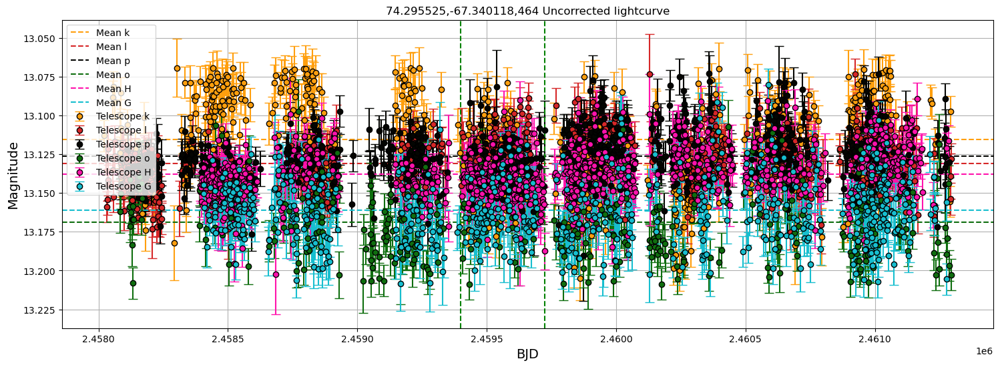

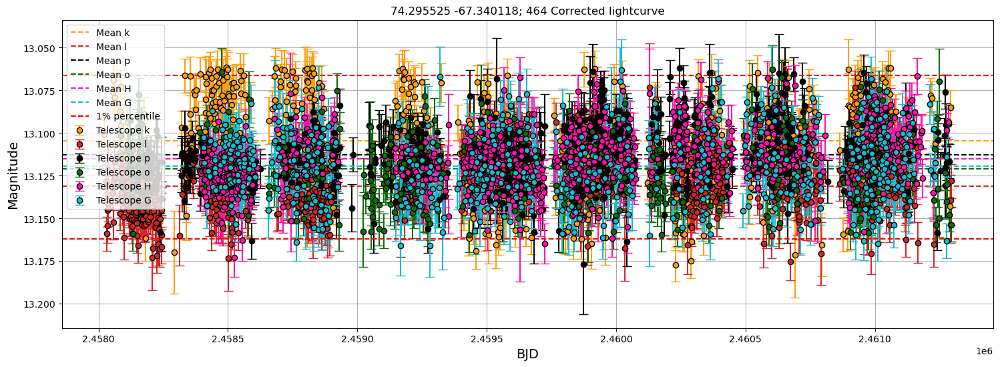

Best frequency: 0.002623 1/day, Best period: 381.30 days, Max power: 0.026, False alarm probability: 6.429e-19
False alarm level for 1.0%: 7.615e-03
Grid sampled at 35777 points


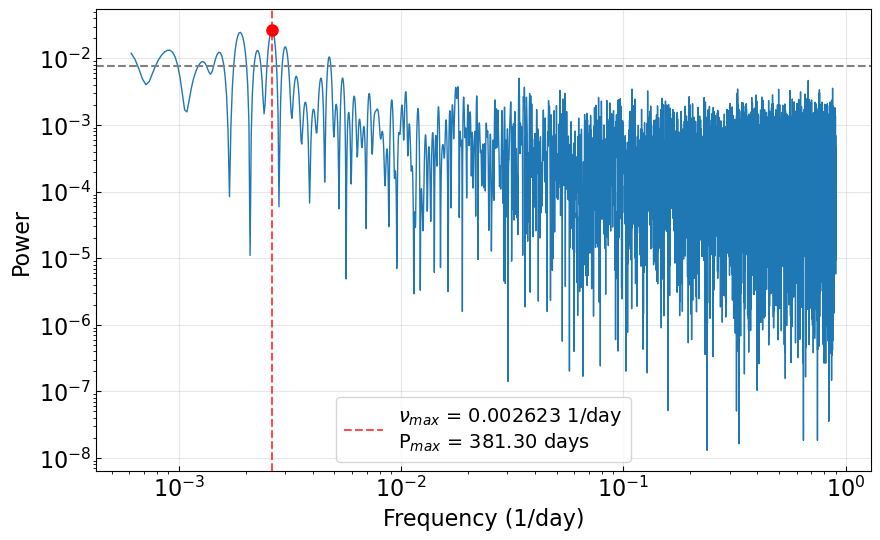

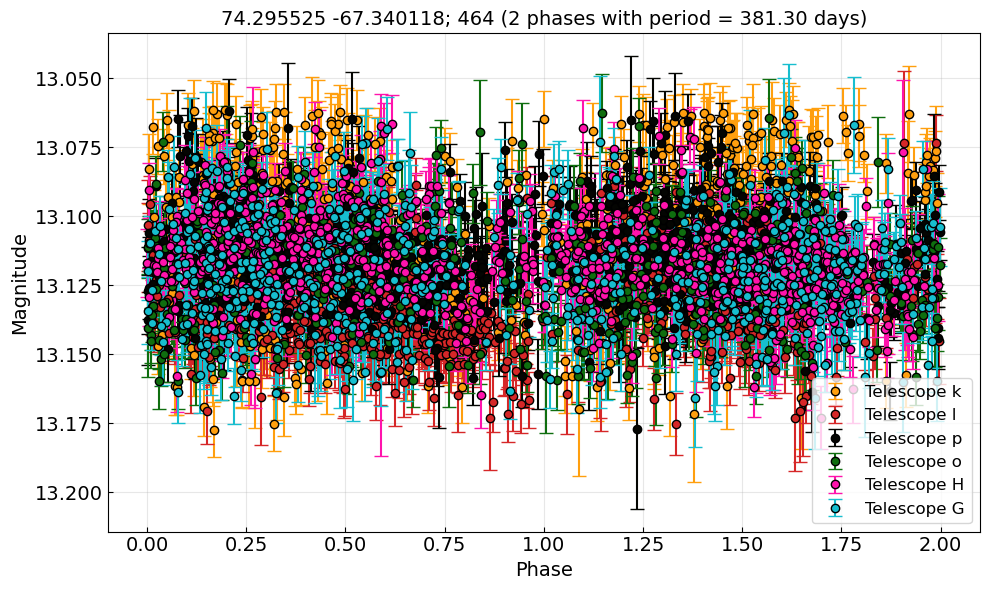

Average scatter (amplitude) per 10 point phase bin: 1.151 mJy


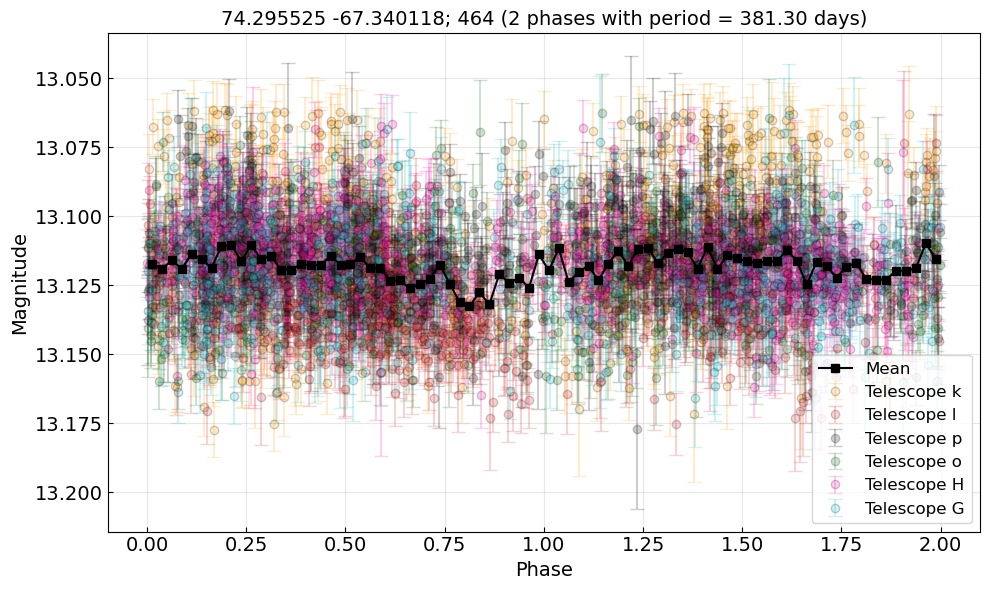

Average scatter (amplitude) per 10 point phase bin: 1.151 mJy
[0.00091311 0.00151645 0.00189354 0.00227064 0.00262259 0.00302482
 0.00475944]
Amplitude metrics:
	Lower 5% percentile: 19.95 mJy, 13.08 mags
	Upper 5% percentile: 21.28 mJy, 13.15 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 1.33 mJy, 0.07 mags
Amplitude metrics:
	Lower 1% percentile: 19.73 mJy, 13.07 mags
	Upper 1% percentile: 21.56 mJy, 13.16 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.82 mJy, 0.10 mags
	Largest amplitude of variability (g-band: True): 2.19 mJy, 0.12 mags
	Average amplitude across all periods: 2.064 mJy
	Standard deviation of amplitudes: 0.094 mJy
	Average amplitude (2.064 mJy) is greater than 5 sigma (0.094 mJy). This indicates consistent variability across periods.
Star index: 466, Best period: 381.4177248053896


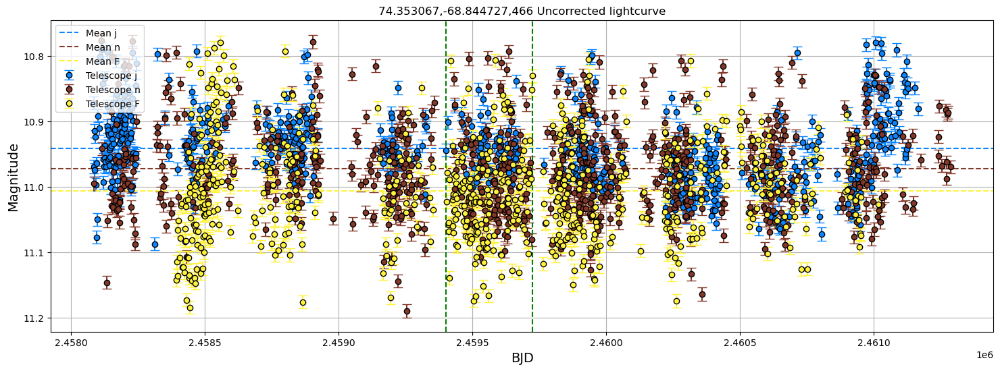

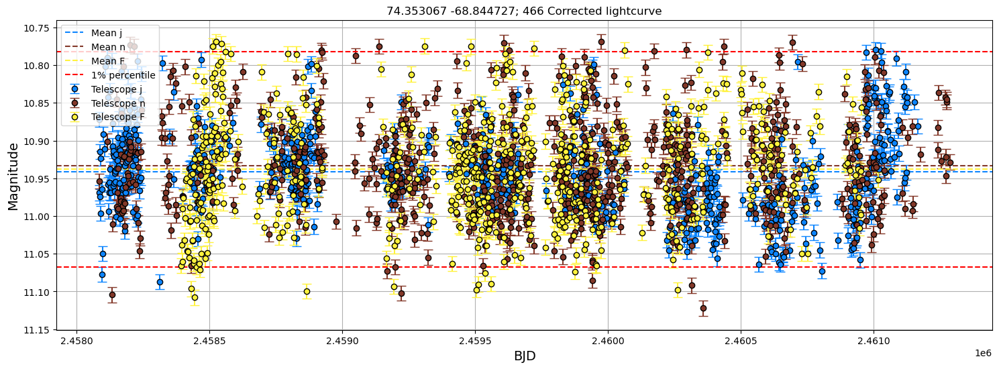

Best frequency: 0.002621 1/day, Best period: 381.56 days, Max power: 0.020, False alarm probability: 4.487e-05
False alarm level for 1.0%: 1.431e-02
Grid sampled at 18023 points


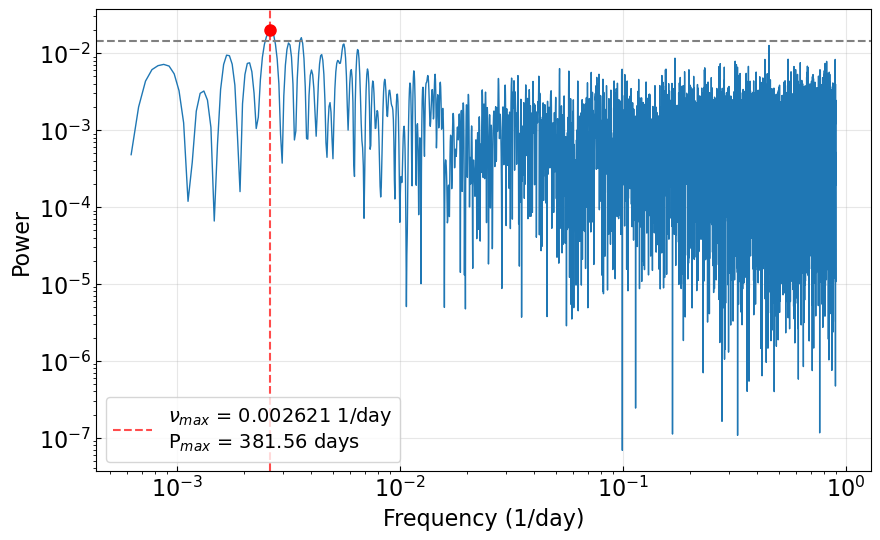

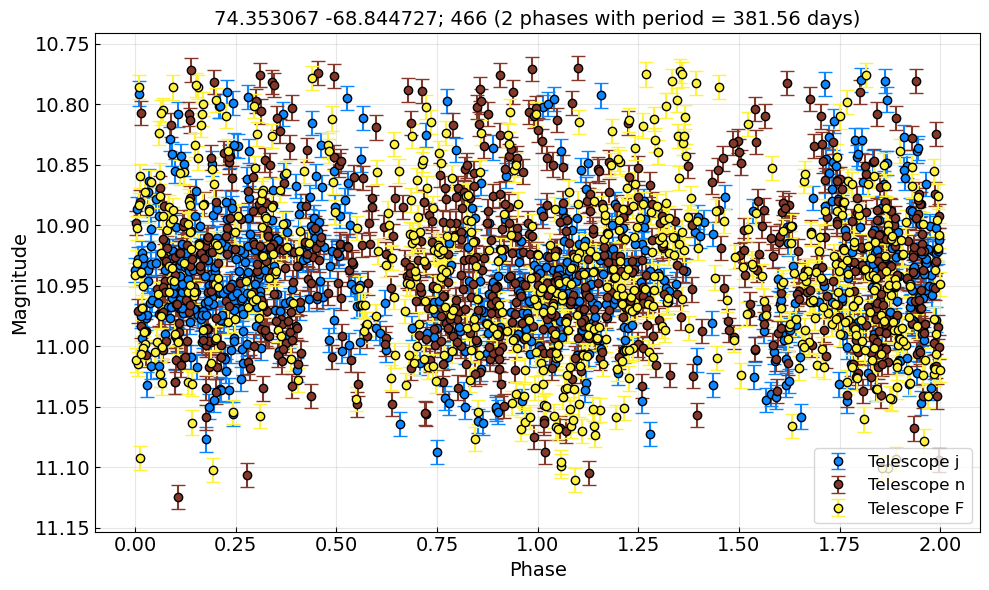

Average scatter (amplitude) per 10 point phase bin: 26.052 mJy


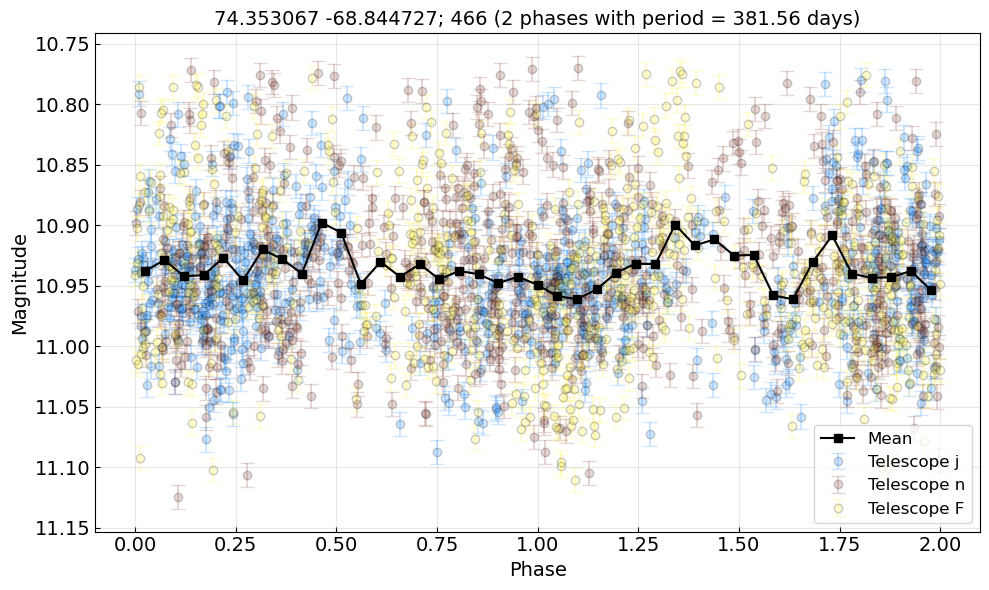

Average scatter (amplitude) per 10 point phase bin: 26.052 mJy
[0.0026208  0.00361889]
Amplitude metrics:
	Lower 5% percentile: 140.24 mJy, 10.82 mags
	Upper 5% percentile: 170.90 mJy, 11.03 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 30.66 mJy, 0.21 mags
Amplitude metrics:
	Lower 1% percentile: 135.80 mJy, 10.78 mags
	Upper 1% percentile: 176.74 mJy, 11.07 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 40.93 mJy, 0.29 mags
	Largest amplitude of variability (g-band: True): 49.70 mJy, 0.35 mags
	Average amplitude across all periods: 46.352 mJy
	Standard deviation of amplitudes: 2.074 mJy
	Average amplitude (46.352 mJy) is greater than 5 sigma (2.074 mJy). This indicates consistent variability across periods.
Star index: 468, Best period: 377.74912770593295


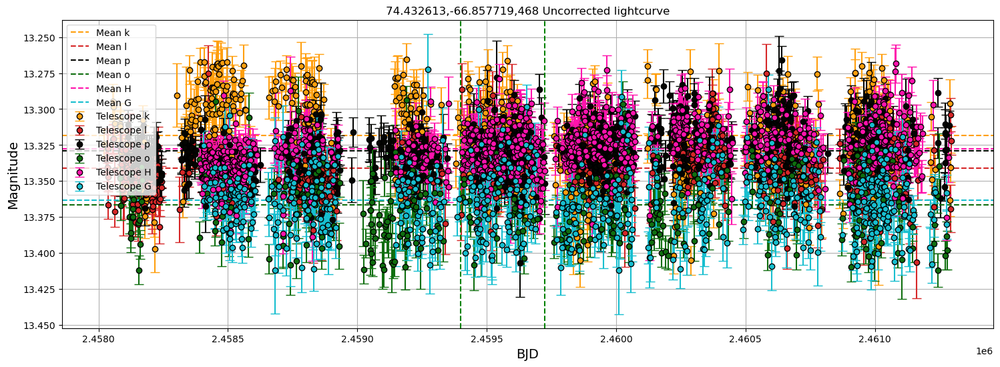

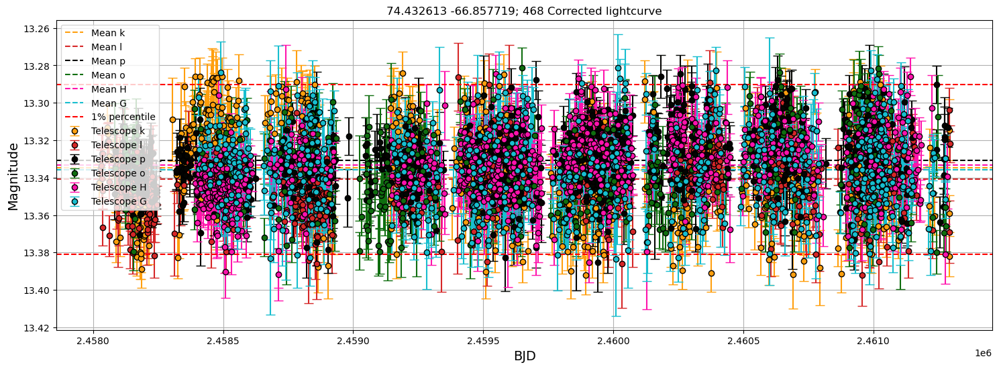

Best frequency: 0.002647 1/day, Best period: 377.75 days, Max power: 0.022, False alarm probability: 3.788e-15
False alarm level for 1.0%: 7.529e-03
Grid sampled at 36227 points


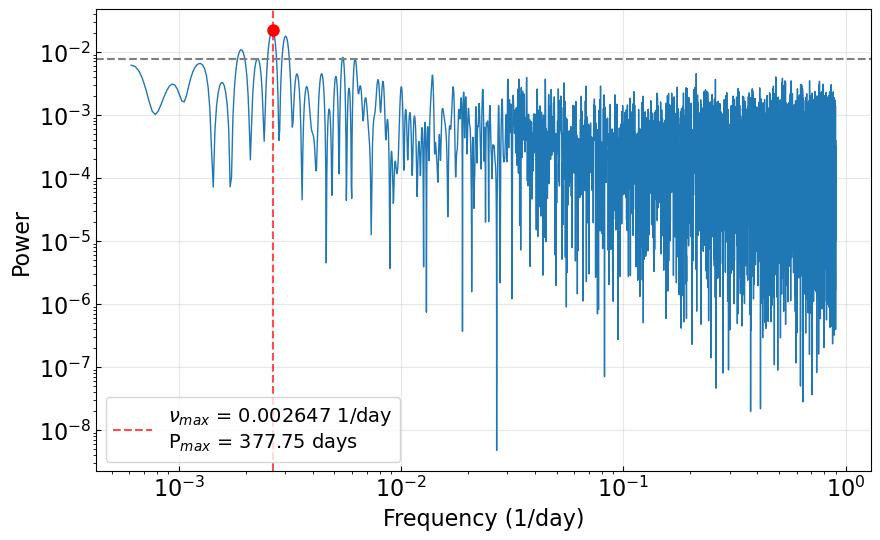

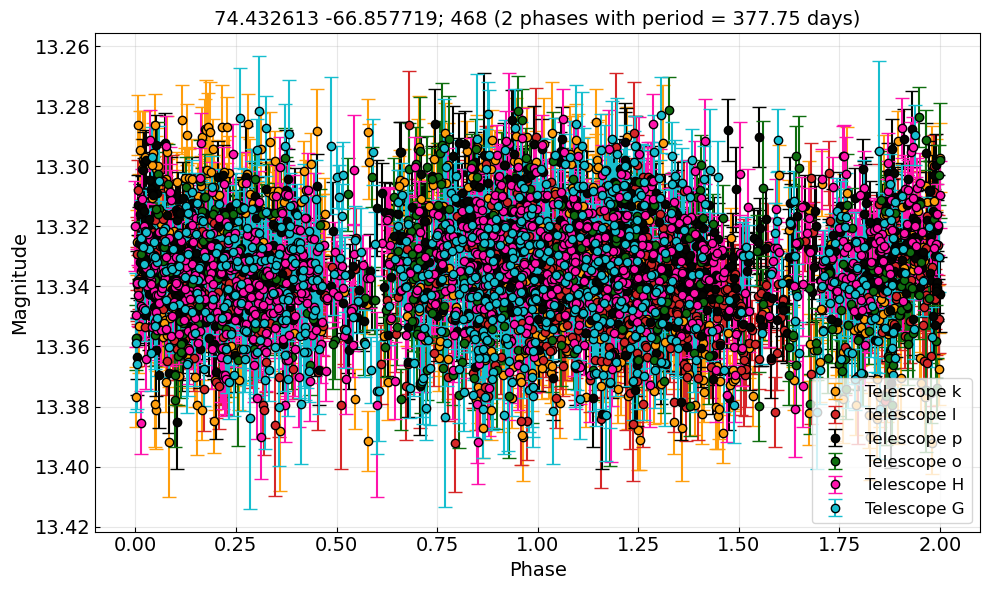

Average scatter (amplitude) per 10 point phase bin: 0.875 mJy


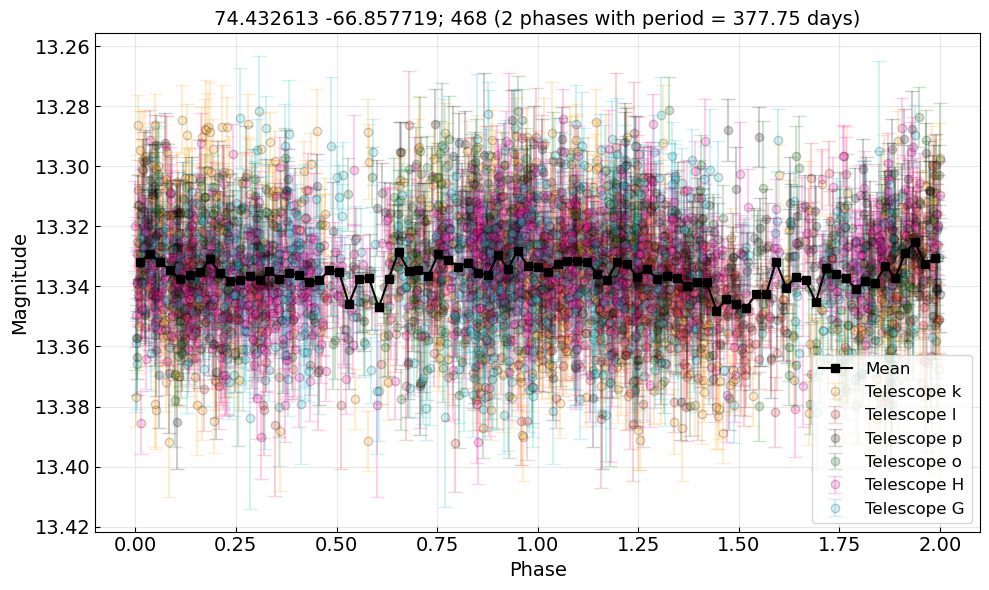

Average scatter (amplitude) per 10 point phase bin: 0.875 mJy
[0.00190244 0.00227485 0.00264726 0.00301967 0.00547756 0.00622237]
Amplitude metrics:
	Lower 5% percentile: 16.31 mJy, 13.30 mags
	Upper 5% percentile: 17.35 mJy, 13.37 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 1.03 mJy, 0.07 mags
Amplitude metrics:
	Lower 1% percentile: 16.13 mJy, 13.29 mags
	Upper 1% percentile: 17.54 mJy, 13.38 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 1.41 mJy, 0.09 mags
	Largest amplitude of variability (g-band: True): 1.71 mJy, 0.11 mags
	Average amplitude across all periods: 1.640 mJy
	Standard deviation of amplitudes: 0.075 mJy
	Average amplitude (1.640 mJy) is greater than 5 sigma (0.075 mJy). This indicates consistent variability across periods.


In [5]:
for star_idx in other_alias_380['star_idx'][10:20]:
    print(f"Star index: {star_idx}, Best period: {other_alias_380.loc[star_idx, 'best_period']}")
    info(star_idx)